# Chapter 7: Neural Networks — From Perceptrons to Multi-Layer Networks

## Overview

This chapter builds feed-forward neural networks from the ground up: the perceptron, the
multi-layer perceptron (MLP) trained by backpropagation, and the same model in scikit-learn,
Keras 3 and PyTorch. Every model is trained on real, openly licensed NFL wide-receiver
statistics from the nflverse project, and every neural-network result is reported next to
simple baselines (majority class / mean, a persistence rule, and linear or logistic
regression). The numbers quoted in the text are produced by the code cells in this
notebook.

## Learning Objectives

- **LO1 — Explain** the perceptron learning rule and when it is guaranteed to converge
  (linearly separable data only), and use the pocket and averaged variants on non-separable data.
- **LO2 — Derive** backpropagation for a fully connected network with the chain rule, including the
  output error $(\hat{y}-y)/m$ for binary cross-entropy and squared error.
- **LO3 — Implement** an MLP from scratch in NumPy with He/Glorot initialisation, and **verify** it with
  a central-difference gradient check and unit tests (including XOR).
- **LO4 — Evaluate** neural networks honestly: temporal train/validation/test splits, scaling inside
  pipelines fit on training data only, scaled regression targets, and baselines next to every result.
- **LO5 — Implement** the same network in scikit-learn, Keras 3 and PyTorch under one training protocol and
  **interpret** the differences between their results.
- **LO6 — Tune** architecture, activation and regularisation on a validation set, and **judge** when a neural
  network is (and is not) worth its extra complexity on small tabular data.

## Why (Intuition & Use-Cases)

A linear model can only draw straight decision boundaries in its input features. Stacking linear maps
with non-linear activations lets a network build its own intermediate features, so an MLP with one
hidden layer of sufficient width can approximate any continuous function on a compact set
{cite}`cybenko1989approximation,hornik1989multilayer`. The theorem says such a network *exists*; it
says nothing about how much data or optimisation is needed to find it. That gap is a theme of this
chapter: on the small tabular dataset used here, a well-regularised MLP is roughly as good as logistic
regression, and on typical tabular benchmarks gradient-boosted trees remain strong competitors
{cite}`grinsztajn2022tree`. Neural networks dominate where data are large and have structure that
learned representations exploit — images, audio, text and other sequences
{cite}`lecun2015deep,goodfellow2016deep`.

### Historical Context

- **1943–1969, threshold units and perceptrons.** McCulloch and Pitts modelled neurons as threshold logic
  units {cite}`mcculloch1943logical`. Rosenblatt's perceptron (1958) learned its weights from data
  {cite}`rosenblatt1958perceptron`, and Novikoff (1962) proved that the perceptron rule converges in a
  finite number of updates *when the data are linearly separable* {cite}`novikoff1962convergence`.
- **1969–early 1980s, the first slowdown.** Minsky and Papert analysed what single-layer perceptrons
  cannot compute {cite}`minsky1969perceptrons`. Their book is often blamed for the decline of neural-network
  research, but that is contested: funding for AI more broadly was cut in the same period, notably in the
  UK after the Lighthill report {cite}`lighthill1973artificial`, and there was not yet a practical
  method for training multi-layer networks.
- **Backpropagation.** Reverse-mode automatic differentiation — the algorithm underlying backpropagation —
  was described by Linnainmaa in 1970 {cite}`linnainmaa1970representation`. Werbos proposed applying it to
  train neural networks in his 1974 thesis and published the neural-network formulation in 1982
  {cite}`werbos1974beyond,werbos1982applications`. Rumelhart, Hinton and Williams (1986) popularised the
  method and showed that it learns useful internal (hidden-layer) representations
  {cite}`rumelhart1986learning`.
- **Late 1980s–1990s.** Universal approximation theorems {cite}`cybenko1989approximation,hornik1989multilayer`,
  convolutional networks for document recognition {cite}`lecun1998gradient` and LSTMs
  {cite}`hochreiter1997long` all date from this period. Even so, through the late 1990s and 2000s neural
  networks were largely overshadowed by kernel methods and tree ensembles: deep networks were hard to train
  (vanishing and exploding gradients {cite}`bengio1994learning`), data sets were small and compute was scarce.
- **2006–2012 revival.** Layer-wise pre-training of deep belief nets {cite}`hinton2006fast`, better
  initialisation {cite}`glorot2010understanding` and rectified linear units {cite}`nair2010rectified` made deep
  networks trainable. In 2012, AlexNet — a GPU-trained convolutional network — won the ImageNet challenge by a
  wide margin {cite}`krizhevsky2012imagenet`, and deep learning became mainstream {cite}`lecun2015deep`.
- **2017–today, transformers.** The transformer {cite}`vaswani2017attention` replaced recurrence with attention
  and is now the dominant architecture for language, and widely used for vision, speech and multimodal models;
  today's large language models are transformers. The MLP studied in this chapter survives inside them: every
  transformer block contains a position-wise feed-forward MLP.

### The framework landscape (October 2026)

- **PyTorch** {cite}`paszke2019pytorch` is the most widely used framework in research and is also common in
  production, with `torch.compile`, `torch.export` and ExecuTorch for on-device deployment.
- **JAX** {cite}`bradbury2018jax` provides composable transformations (`grad`, `jit`, `vmap`) and is used for
  large-scale training, notably at Google.
- **Keras 3** {cite}`chollet2015keras` is a multi-backend API: the same model code runs on JAX, TensorFlow or
  PyTorch. **TensorFlow 2** {cite}`abadi2016tensorflow` (eager execution by default since 2.0) remains in use
  in production pipelines; its mobile runtime TensorFlow Lite has been renamed **LiteRT**.
- **scikit-learn** {cite}`pedregosa2011scikit` offers `MLPClassifier`/`MLPRegressor`: convenient for small tabular
  problems, CPU-only, and without GPU support or custom layers.

The old rule of thumb "TensorFlow for production, PyTorch for research" predates TensorFlow 2's eager mode and
Keras 3; it no longer describes the landscape.

### Ethics & Legality

- **Licence.** The data are from the nflverse project and are released under CC BY 4.0, which permits reuse with
  attribution; the attribution is given in the Data section.
- **People in the data.** The rows describe named professional athletes. We use only public on-field statistics and
  make no claims about health, character or contract value; error analysis lists names only alongside the statistics
  that produced the prediction.
- **Use of predictions.** A model of next-season production is a noisy forecast, not a judgement of a person. Its
  errors are not uniform (for example, it cannot see injuries or role changes), so it should not drive decisions
  about individuals on its own.

### Assumptions & Failure Modes

- **Assumptions:** examples are representative of the period the model is applied to; features are available at
  prediction time (no look-ahead); the training set is large enough for the number of parameters.
- **Failure modes:** overfitting small data sets; poor initialisation or learning rates (vanishing/exploding
  gradients, dead ReLUs); silent shape bugs (for example broadcasting a $(m,)$ label vector against an $(m,1)$
  prediction); distribution shift between seasons; and reporting a network without a baseline, which hides
  whether it helps at all.

## Math

### The artificial neuron and the perceptron

A neuron computes a weighted sum followed by an activation: $a = f(\mathbf{w}^\top\mathbf{x} + b)$.
The perceptron uses the sign function, $\hat{y} = \operatorname{sign}(\mathbf{w}^\top\mathbf{x}+b)$ with labels
$y\in\{-1,+1\}$, and the update rule

$$\text{if } y_i(\mathbf{w}^\top\mathbf{x}_i + b) \le 0:\quad \mathbf{w}\leftarrow\mathbf{w}+\eta\,y_i\mathbf{x}_i,\quad b\leftarrow b+\eta\,y_i .$$

**Convergence theorem** {cite}`novikoff1962convergence`. If some unit vector $\mathbf{u}$ separates the data with margin
$\gamma>0$ (i.e. $y_i\,\mathbf{u}^\top\tilde{\mathbf{x}}_i\ge\gamma$, with $\tilde{\mathbf{x}}$ the input augmented with a
constant 1) and $\lVert\tilde{\mathbf{x}}_i\rVert\le R$, the perceptron makes at most $(R/\gamma)^2$ updates. If the data are
**not** linearly separable the theorem does not apply and the weights never settle; the *pocket* algorithm
{cite}`gallant1990perceptron` keeps the best weights seen so far, and the *averaged* perceptron
{cite}`freund1999large` predicts with the average of all intermediate weight vectors. The perceptron rule is not
gradient descent on a smooth loss (it is a sub-gradient step on the non-differentiable loss
$\max(0,-y_i(\mathbf{w}^\top\mathbf{x}_i+b))$), which is why it has no notion of "how wrong" a prediction is.

### Multi-layer perceptrons

With row-vector examples stacked in $X\in\mathbb{R}^{m\times d}$, layer $\ell=1,\dots,L$ computes

$$Z^{(\ell)} = A^{(\ell-1)}W^{(\ell)} + \mathbf{1}\mathbf{b}^{(\ell)},\qquad A^{(\ell)} = f\big(Z^{(\ell)}\big),\qquad A^{(0)}=X,$$

with $W^{(\ell)}\in\mathbb{R}^{n_{\ell-1}\times n_\ell}$. The output layer has one unit and no hidden activation:
$z = Z^{(L)}\in\mathbb{R}^{m\times 1}$.

**Activations.** $\operatorname{ReLU}(z)=\max(0,z)$; $\tanh(z)$; $\sigma(z)=1/(1+e^{-z})$ with
$\sigma'(z)=\sigma(z)(1-\sigma(z))\le 1/4$, which is one source of vanishing gradients in deep sigmoid networks.

### Losses (averaged over the $m$ examples of a batch)

- **Binary cross-entropy** with $p=\sigma(z)$:
  $\displaystyle L = -\frac1m\sum_{i=1}^m\big[y_i\log p_i + (1-y_i)\log(1-p_i)\big] = \frac1m\sum_i\big[\operatorname{softplus}(z_i)-y_iz_i\big].$
  The right-hand form is computed from the logit and never takes $\log 0$.
- **Squared error** (regression): $\displaystyle L = \frac{1}{2m}\sum_{i=1}^m(z_i-y_i)^2$. The factor $\tfrac12$ cancels
  the 2 from differentiation; with the plain mean squared error the gradient is simply twice as large.

Both choices give the same output error, which is why classification and regression share one backward pass:

$$\delta^{(L)} = \frac{\partial L}{\partial Z^{(L)}} = \frac{1}{m}(\hat{\mathbf{y}}-\mathbf{y}),\qquad \hat{\mathbf{y}} = \sigma(z)\ \text{or}\ z .$$

Here $\mathbf{y}$ must have shape $(m,1)$, like $\hat{\mathbf{y}}$. A label vector of shape $(m,)$ broadcasts against
$(m,1)$ to an $(m,m)$ matrix — a silent bug that is demonstrated in Part 2.

### Backpropagation

Applying the chain rule layer by layer (with $\odot$ the element-wise product):

$$\frac{\partial L}{\partial W^{(\ell)}} = A^{(\ell-1)\top}\delta^{(\ell)},\qquad
\frac{\partial L}{\partial \mathbf{b}^{(\ell)}} = \mathbf{1}^\top\delta^{(\ell)},\qquad
\delta^{(\ell-1)} = \big(\delta^{(\ell)}W^{(\ell)\top}\big)\odot f'\big(Z^{(\ell-1)}\big).$$

Because $\delta^{(L)}$ already contains the factor $1/m$, every gradient is an average over the batch. An L2 penalty
$\tfrac{\lambda}{2}\sum_\ell\lVert W^{(\ell)}\rVert_F^2$ adds $\lambda W^{(\ell)}$ to each weight gradient.

### Initialisation

To keep activation variances roughly constant across layers: **He** initialisation, $W\sim\mathcal{N}(0,\,2/n_{\text{in}})$,
for layers followed by ReLU {cite}`he2015delving`; **Glorot** (Xavier) uniform initialisation,
$W\sim\mathcal{U}\big(-\sqrt{6/(n_{\text{in}}+n_{\text{out}})},\,\sqrt{6/(n_{\text{in}}+n_{\text{out}})}\big)$, for tanh, sigmoid and
linear outputs {cite}`glorot2010understanding`. Biases start at zero.

### Complexity

A dense layer from $n_{\ell-1}$ to $n_\ell$ units costs $n_{\ell-1}n_\ell$ multiply–adds per example. For input
dimension $d$, $l$ hidden layers of width $h$ and one output:

- **Parameters:** $P = (d+1)h + (l-1)(h+1)h + (h+1) = O(dh + l h^2)$.
- **Forward pass:** $O(dh + l h^2)$ per example; the backward pass costs about twice as much.
- **Training:** $O\big(e\cdot n\cdot(dh + l h^2)\big)$ for $e$ epochs over $n$ examples — linear in $n$, quadratic in width.
- **Memory:** $O(P)$ for the weights (Adam keeps two more copies), plus $O(B\,(d + l h))$ stored activations for a
  batch of $B$ examples during backpropagation.

## How (Algorithm & Pseudocode)

### Perceptron (with pocket and averaged variants)

```
w, b <- 0;  pocket <- (w, b);  sum <- 0;  steps <- 0
for epoch = 1..E:
    updates <- 0
    for (x_i, y_i) in shuffled training data:          # y_i in {-1, +1}
        if y_i (w.x_i + b) <= 0:  w <- w + eta y_i x_i;  b <- b + eta y_i;  updates += 1
        sum <- sum + (w, b);  steps += 1                # averaged perceptron
    if training errors of (w, b) < training errors of pocket:  pocket <- (w, b)
    if updates == 0: stop                               # converged (only possible if separable)
return (w, b), pocket, sum / steps
```

### Mini-batch training of an MLP

```
initialise W (He for ReLU layers, Glorot otherwise), b = 0
for epoch = 1..E:
    for each mini-batch (X_B, y_B) of a fresh shuffle:
        forward:   Z_l = A_{l-1} W_l + b_l ;  A_l = f(Z_l)     (output layer: raw score z)
        output:    delta_L = (yhat - y_B) / |B|               (y_B reshaped to (|B|, 1))
        backward:  dW_l = A_{l-1}^T delta_l + lambda W_l ;  db_l = column sums of delta_l
                   delta_{l-1} = (delta_l W_l^T) * f'(Z_{l-1})
        update:    Adam (or SGD with momentum) step on every W_l, b_l
    record training loss and validation loss
    early stopping: keep the parameters with the lowest validation loss; stop after
                    `patience` epochs without improvement
```

Adam {cite}`kingma2014adam` keeps exponential moving averages of the gradient and its square and divides one by the square
root of the other, giving each parameter its own step size; see {cite}`ruder2016overview` for a survey of optimisers.

### Hyperparameters used in this chapter

| Hyperparameter | Values used (and where) |
|---|---|
| Hidden layer sizes | (4,) for XOR; (16,) for the 1,000-yard task (Part 2); (32, 16) in Parts 3–4; grid (8,), (32,), (32, 16), (64, 32, 16) in Part 5 |
| Activation | tanh in Part 2 (XOR and the 1,000-yard task); ReLU in Parts 3–4; both ReLU and tanh in Part 5 |
| Optimiser | SGD with momentum 0.9, full batch, for XOR; Adam everywhere else (scikit-learn's `solver="adam"` in Parts 3 and 5) |
| Learning rate | 0.5 for XOR (SGD); $10^{-2}$ for the 1,000-yard task (Part 2); $10^{-3}$ in Parts 3–5 (scikit-learn's default in Parts 3 and 5) |
| Batch size | full batch (4 rows) for XOR; 32 in Part 2 and Part 4; scikit-learn's default `min(200, n)` = 200 in Parts 3 and 5 |
| L2 strength | none in Part 2 and Part 4; `alpha` = $10^{-4}$ (scikit-learn default, deliberately untuned) for the Part 3 classifier; regression MLP `alpha` tuned over $10^{-4}, 10^{-2}, 1, 10, 100$ on the validation seasons (Part 3); classifier grid $10^{-4}, 10^{-2}, 1, 10$ (Part 5) |
| Stopping | early stopping on validation loss with patience 50 (Part 2, at most 1,000 epochs) and patience 20 (Part 4, at most 500 epochs); in Parts 3 and 5, scikit-learn's own rule (training loss improves by less than `tol` = $10^{-4}$ for 10 epochs), with `max_iter` 2,000 (Part 3 classifier) or 10,000 (Part 3 regressor, Part 5) |

## Setup

Imports, seeding and the environment record. Warnings are **not** filtered anywhere in this notebook: if a model
fails to converge, scikit-learn's `ConvergenceWarning` will appear in the output. The only verbosity setting is
`TF_CPP_MIN_LOG_LEVEL=1`, which hides TensorFlow's C++ *informational* start-up line (TensorFlow warnings and errors
are still shown).

Keras 3 is multi-backend; the backend is chosen with the `KERAS_BACKEND` environment variable *before* Keras is first
imported. This notebook uses the **PyTorch backend**. With the TensorFlow backend in this environment (tensorflow-cpu
2.21 with Keras 3.15), `model.fit` triggers TensorFlow C++ error-log lines about an unknown `tf.data` attribute (a
version mismatch between the two packages); the model code itself is backend-independent, so Homework 6 asks you to
switch to the JAX or TensorFlow backend and compare.

In [1]:
import copy
import os
import platform
import random
import sys
import time
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "torch")      # must be set before the first `import keras`
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")   # Keras imports TensorFlow if installed; hide its C++ INFO lines only

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.plot_utils import configure_plotting
from utils.nfl_data import (ASSET_URL_TEMPLATE, LICENSE_NAME, LICENSE_URL, RELEASE_URL,
                            file_digests, load_receiving_seasons)

configure_plotting(style="seaborn-v0_8", figsize=(10, 5))
pd.set_option("display.width", 140)
pd.set_option("display.precision", 3)

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    """Seed Python, NumPy, PyTorch and Keras/TensorFlow."""
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except ModuleNotFoundError:
        pass
    try:
        import keras
        keras.utils.set_random_seed(seed)   # seeds Python, NumPy and the active backend
    except ModuleNotFoundError:
        pass


def installed_version(*distributions: str) -> str:
    """Version of the first installed distribution among alternatives (e.g. tensorflow / tensorflow-cpu)."""
    for name in distributions:
        try:
            return f"{name} {version(name)}"
        except PackageNotFoundError:
            continue
    return f"{distributions[0]} not installed"


PACKAGES = [("numpy",), ("pandas",), ("scikit-learn",), ("scipy",), ("matplotlib",), ("joblib",),
            ("torch",), ("tensorflow", "tensorflow-cpu"), ("keras",)]

seed_everything(SEED)
print(f"Python {platform.python_version()} on {platform.system()} {platform.machine()}")
for alternatives in PACKAGES:
    print("  " + installed_version(*alternatives))

Python 3.12.12 on Linux x86_64
  numpy 2.5.4
  pandas 3.0.6
  scikit-learn 1.9.1
  scipy 1.18.1
  matplotlib 3.11.2
  joblib 1.6.0
  torch 2.14.1+cpu
  tensorflow-cpu 2.21.0
  keras 3.15.1


## Data (Sources, EDA, Splits)

### Source and licence

- **Dataset:** nflverse-data, release `stats_player`, files `stats_player_reg_<season>.csv` (regular season, one row per
  player-season), produced with `nflfastR::calculate_stats()` from NFL play-by-play data {cite}`nflverse2026stats`.
- **URL:** <https://github.com/nflverse/nflverse-data/releases/tag/stats_player>
- **Licence:** CC BY 4.0 (<https://github.com/nflverse/nflverse-data/blob/master/LICENSE.md>).
  Attribution: *Data: nflverse (nflverse-data, `stats_player` release), CC BY 4.0.*
- **Accessed:** 2026-10-19. Seasons 2012–2025 (the 2026 season was in progress and is not used).
- **Reproducibility:** `utils/nfl_data.py` downloads each file once into `data/nflverse/` (git-ignored) and checks it
  against a SHA-256 digest pinned on the access date. If a download fails, or nflverse later re-publishes a file with
  different contents, the loader raises an error instead of substituting other data; the error message explains how to
  accept rebuilt files deliberately (`verify=False`), in which case some numbers quoted in the text may differ. There is
  no synthetic fallback.

### Prediction tasks

1. **Main task — next-season production (Parts 3–5).** For every wide receiver (WR) season $t$ with at least 6 games
   and 20 targets, use 14 per-game and efficiency statistics from season $t$ to predict season $t+1$:
   - *classification:* will the player gain at least $1000/17\approx 58.8$ receiving yards per game in season $t+1$
     (a 1,000-yard pace over a 17-game season)?
   - *regression:* receiving yards per game in season $t+1$.

   Only players who also appear as a WR with at least 6 games in season $t+1$ are included, so the task is "how
   productive will a receiver be *if he plays*", not "will he play".
2. **Teaching task — 1,000-yard seasons (Parts 1–2).** For WR seasons with at least 10 receptions, classify whether the
   season reached 1,000 receiving yards from two inputs: receptions and yards per reception. Because
   yards $=$ receptions $\times$ yards per reception, the class boundary is the curve
   $\text{rec}\times\text{ypr}=1000$: curved in the raw inputs, but a straight line in their logarithms. That makes this
   real data set a clean test bed for linear separability.

### Splits

- **Main task:** split by season to mimic forecasting — train on $t\in$ 2012–2020, validate on $t\in$ 2021–2022, test on
  $t\in$ 2023–2024 (outcomes in 2024–2025). The test set is used once per final model.
- **Teaching task:** a stratified random 60/20/20 train/validation/test split (seed 42).
- All scaling is fit on training rows only (inside scikit-learn `Pipeline`s, or a `StandardScaler` fit on the training
  split for the deep-learning frameworks).

### Leakage checks

Features for the main task come only from season $t$; the target only from season $t+1$; the three splits have
disjoint target seasons. Player identifiers and names are never used as features. The code below asserts that each
(player, season) pair appears once and that splits do not overlap.

In [2]:
SEASONS = list(range(2012, 2026))
ACCESS_DATE = "2026-10-19"
DATA_DIR = PROJECT_ROOT / "data" / "nflverse"

raw = load_receiving_seasons(SEASONS, cache_dir=DATA_DIR)   # raises on download failure or checksum mismatch
print(f"Source : {RELEASE_URL}")
print(f"Files  : {ASSET_URL_TEMPLATE.format(season='<season>')}")
print(f"Licence: {LICENSE_NAME} ({LICENSE_URL}); accessed {ACCESS_DATE}")
print(f"Loaded {len(raw):,} player-season rows x {raw.shape[1]} columns for seasons {SEASONS[0]}-{SEASONS[-1]}")
digests = file_digests(SEASONS, cache_dir=DATA_DIR)
print("SHA-256 (first 12 hex digits):", {s: d[:12] for s, d in digests.items()})

wr = raw[raw["position"] == "WR"].copy()
assert not wr.duplicated(["player_id", "season"]).any(), "player-season rows must be unique"
print(f"\nWide-receiver rows: {len(wr):,}")
display(wr.groupby("season").size().rename("WR rows").to_frame().T)

Source : https://github.com/nflverse/nflverse-data/releases/tag/stats_player
Files  : https://github.com/nflverse/nflverse-data/releases/download/stats_player/stats_player_reg_<season>.csv
Licence: CC BY 4.0 (https://github.com/nflverse/nflverse-data/blob/master/LICENSE.md); accessed 2026-10-19
Loaded 26,830 player-season rows x 148 columns for seasons 2012-2025
SHA-256 (first 12 hex digits): {2012: '6cdfbf3b291c', 2013: '342fd27eef61', 2014: '9f7aee274ddd', 2015: '91cc6edbfe16', 2016: '17063fa01736', 2017: 'ee3ed8e1b9f7', 2018: '8d66bc2dde26', 2019: '324b77e60278', 2020: 'ac90bb97fd0c', 2021: '2edb2190fa41', 2022: 'af2d534b208a', 2023: '0cc79526a678', 2024: 'fbad4e9f1b89', 2025: 'aaa8559478dd'}

Wide-receiver rows: 3,151


season,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
WR rows,216,206,205,212,210,214,228,230,233,256,239,225,236,241


In [3]:
def add_rate_features(df: pd.DataFrame) -> pd.DataFrame:
    """Per-game and efficiency statistics for one season."""
    out = df.copy()
    g = out["games"]
    out["targets_pg"] = out["targets"] / g
    out["receptions_pg"] = out["receptions"] / g
    out["yards_pg"] = out["receiving_yards"] / g
    out["tds_pg"] = out["receiving_tds"] / g
    out["first_downs_pg"] = out["receiving_first_downs"] / g
    out["catch_rate"] = out["receptions"] / out["targets"]
    out["yards_per_target"] = out["receiving_yards"] / out["targets"]
    out["adot"] = out["receiving_air_yards"] / out["targets"]          # average depth of target
    out["yac_per_rec"] = out["receiving_yards_after_catch"] / out["receptions"].clip(lower=1)
    out["epa_per_target"] = out["receiving_epa"] / out["targets"]
    return out


FEATURES = ["games", "targets_pg", "receptions_pg", "yards_pg", "tds_pg", "first_downs_pg",
            "catch_rate", "yards_per_target", "adot", "yac_per_rec", "epa_per_target",
            "target_share", "air_yards_share", "wopr"]
THRESHOLD = 1000 / 17                      # yards per game for a 1,000-yard 17-game pace

wr = add_rate_features(wr)
current = wr[(wr["games"] >= 6) & (wr["targets"] >= 20)]
following = (wr[wr["games"] >= 6][["player_id", "season", "yards_pg", "games"]]
             .rename(columns={"yards_pg": "next_yards_pg", "games": "next_games"})
             .assign(season=lambda d: d["season"] - 1))
data = current.merge(following, on=["player_id", "season"], how="inner", validate="one_to_one")
data["y"] = (data["next_yards_pg"] >= THRESHOLD).astype(int)
assert data[FEATURES].notna().all().all() and np.isfinite(data[FEATURES].to_numpy()).all()

split = np.select([data["season"] <= 2020, data["season"] <= 2022], ["train", "validation"], "test")
data["split"] = split
train, val, test = (data[data["split"] == s].reset_index(drop=True) for s in ["train", "validation", "test"])
assert set(train["season"] + 1).isdisjoint(set(val["season"] + 1) | set(test["season"] + 1))
assert set(val["season"] + 1).isdisjoint(set(test["season"] + 1))

X_train, X_val, X_test = (d[FEATURES].to_numpy(float) for d in (train, val, test))
y_train, y_val, y_test = (d["y"].to_numpy() for d in (train, val, test))
r_train, r_val, r_test = (d["next_yards_pg"].to_numpy(float) for d in (train, val, test))

print(f"Eligible WR seasons with a qualifying next season: {len(data):,} "
      f"(of {len(current):,} eligible seasons; {len(current) - len(data):,} have no qualifying next season)")
summary = (data.groupby("split", sort=False)
           .agg(rows=("y", "size"), seasons_t=("season", lambda s: f"{s.min()}-{s.max()}"),
                positive_rate=("y", "mean"), mean_next_yards_pg=("next_yards_pg", "mean"))
           .reindex(["train", "validation", "test"]))
display(summary)
display(data[FEATURES + ["next_yards_pg"]].describe().T[["mean", "std", "min", "50%", "max"]])

Eligible WR seasons with a qualifying next season: 1,324 (of 1,839 eligible seasons; 515 have no qualifying next season)


,rows,seasons_t,positive_rate,mean_next_yards_pg
split,,,,
train,892,2012-2020,0.270,43.955
validation,216,2021-2022,0.245,40.891
test,216,2023-2024,0.227,40.141


,mean,std,min,50%,max
games,13.910,2.644,6.000,15.000,17.000
targets_pg,5.661,2.393,1.375,5.453,12.750
receptions_pg,3.511,1.635,0.625,3.300,9.312
yards_pg,45.483,22.373,3.357,43.132,122.750
tds_pg,0.281,0.202,0.000,0.250,1.286
first_downs_pg,2.190,1.098,0.143,2.000,5.812
catch_rate,0.615,0.089,0.286,0.619,0.955
yards_per_target,7.909,1.649,2.136,7.907,15.308
adot,10.941,3.077,-1.500,10.907,22.407
yac_per_rec,4.366,1.540,0.500,4.222,12.885


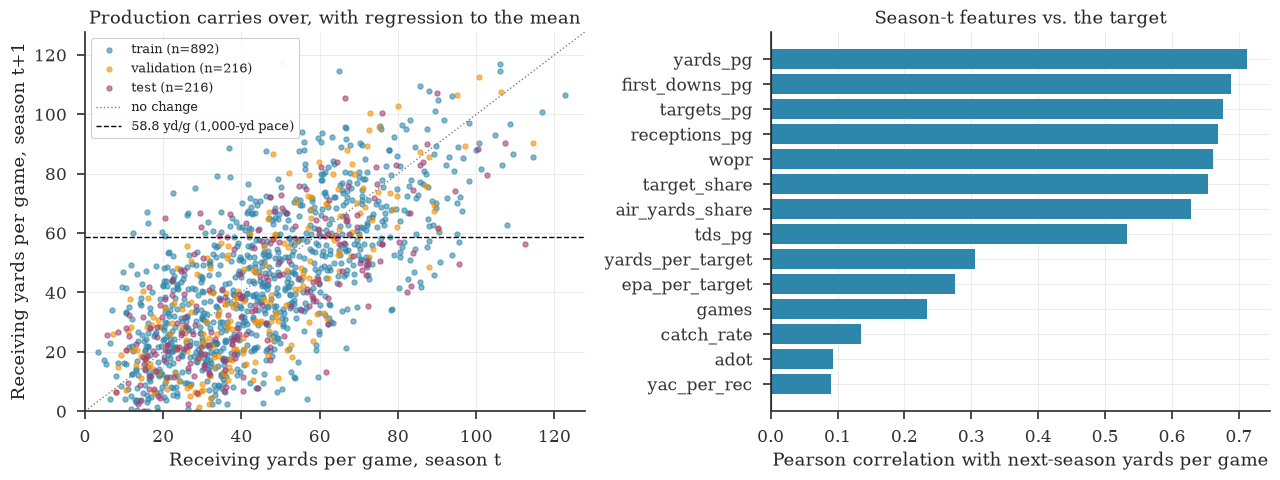

Correlation of yards_pg (t) with next_yards_pg (t+1): 0.711


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for name, d, color in [("train", train, "#2E86AB"), ("validation", val, "#F18F01"), ("test", test, "#A23B72")]:
    ax.scatter(d["yards_pg"], d["next_yards_pg"], s=14, alpha=0.6, color=color, label=f"{name} (n={len(d)})")
lim = [0, max(data["yards_pg"].max(), data["next_yards_pg"].max()) + 5]
ax.plot(lim, lim, color="grey", lw=1, ls=":", label="no change")
ax.axhline(THRESHOLD, color="black", lw=1, ls="--", label=f"{THRESHOLD:.1f} yd/g (1,000-yd pace)")
ax.set(xlim=lim, ylim=lim, xlabel="Receiving yards per game, season t",
       ylabel="Receiving yards per game, season t+1", title="Production carries over, with regression to the mean")
ax.legend(fontsize=9, loc="upper left")

ax = axes[1]
corr = data[FEATURES].corrwith(data["next_yards_pg"]).sort_values()
ax.barh(corr.index, corr.values, color="#2E86AB")
ax.set(xlabel="Pearson correlation with next-season yards per game", title="Season-t features vs. the target")
ax.axvline(0, color="black", lw=0.8)
plt.show()
print("Correlation of yards_pg (t) with next_yards_pg (t+1): "
      f"{data['yards_pg'].corr(data['next_yards_pg']):.3f}")

**What the EDA shows.** Receiving production persists from one season to the next but regresses toward the mean
(points fall below the dotted no-change line at the top end). Volume statistics (targets, receptions, first downs and
yards per game, and team target/air-yard shares) are the most correlated with next-season production; efficiency
statistics such as catch rate and depth of target carry much less linear signal. Roughly a quarter of qualifying
receivers reach the 1,000-yard pace the following season (see the `positive_rate` column), so a classifier must beat
about 75% accuracy just to beat "always predict no" — which is why the tables below report log loss and ROC AUC as well
as accuracy.

## Implementation (From-Scratch)

### Part 1: The perceptron — separable and non-separable data

We first certify linear separability with a linear program (find $\mathbf{w},b$ with $y_i(\mathbf{w}^\top\mathbf{x}_i+b)\ge 1$
for all $i$; it is feasible exactly when the data are separable), then train a from-scratch perceptron on

- **log features** $(\log\text{rec},\ \log\text{ypr})$, where the 1,000-yard boundary is the straight line
  $\log\text{rec}+\log\text{ypr}=\log 1000$, and
- **raw features** (rec, ypr), where the boundary is a hyperbola.

In [5]:
from scipy.optimize import linprog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


class PerceptronFromScratch:
    """Rosenblatt perceptron with pocket (Gallant, 1990) and averaged (Freund & Schapire, 1999) weights.

    Labels are {0, 1} at the interface and {-1, +1} internally. The pocket is updated once per
    epoch, with the full training error of the current weights.
    """

    def __init__(self, learning_rate=1.0, max_epochs=200, random_state=SEED):
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, float)
        s = np.where(np.asarray(y) == 1, 1.0, -1.0)
        rng = np.random.default_rng(self.random_state)
        w, b = np.zeros(X.shape[1]), 0.0
        w_sum, b_sum, steps = np.zeros_like(w), 0.0, 0
        self.pocket_ = (w.copy(), b)
        best_errors = np.inf
        self.updates_per_epoch_, self.train_errors_per_epoch_ = [], []
        self.converged_ = False
        for epoch in range(self.max_epochs):
            updates = 0
            for i in rng.permutation(len(X)):
                if s[i] * (X[i] @ w + b) <= 0:
                    w += self.learning_rate * s[i] * X[i]
                    b += self.learning_rate * s[i]
                    updates += 1
                w_sum += w
                b_sum += b
                steps += 1
            errors = int(np.sum(s * (X @ w + b) <= 0))
            self.updates_per_epoch_.append(updates)
            self.train_errors_per_epoch_.append(errors)
            if errors < best_errors:
                best_errors, self.pocket_ = errors, (w.copy(), b)
            if updates == 0:
                self.converged_ = True
                break
        self.n_epochs_ = epoch + 1
        self.last_ = (w, b)
        self.averaged_ = (w_sum / steps, b_sum / steps)
        return self

    def predict(self, X, weights="last"):
        w, b = {"last": self.last_, "pocket": self.pocket_, "averaged": self.averaged_}[weights]
        return (np.asarray(X, float) @ w + b > 0).astype(int)


def linearly_separable(X, y):
    """LP feasibility test: is there (w, b) with y_i (w.x_i + b) >= 1 for every i?"""
    s = np.where(y == 1, 1.0, -1.0)
    A_ub = -s[:, None] * np.column_stack([X, np.ones(len(X))])
    res = linprog(np.zeros(X.shape[1] + 1), A_ub=A_ub, b_ub=-np.ones(len(X)),
                  bounds=[(None, None)] * (X.shape[1] + 1), method="highs")
    return res.status == 0   # 0 = feasible optimum found, 2 = infeasible


seasons_1k = wr[wr["receptions"] >= 10].copy()
seasons_1k["ypr"] = seasons_1k["receiving_yards"] / seasons_1k["receptions"]
seasons_1k["y"] = (seasons_1k["receiving_yards"] >= 1000).astype(int)
idx_tr, idx_rest = train_test_split(np.arange(len(seasons_1k)), test_size=0.4,
                                    stratify=seasons_1k["y"], random_state=SEED)
idx_va, idx_te = train_test_split(idx_rest, test_size=0.5,
                                  stratify=seasons_1k["y"].to_numpy()[idx_rest], random_state=SEED)
raw_xy = seasons_1k[["receptions", "ypr"]].to_numpy(float)
y1k = seasons_1k["y"].to_numpy()
print(f"1,000-yard task: {len(seasons_1k):,} WR seasons (2012-2025, >=10 receptions), "
      f"{y1k.sum()} reached 1,000 yards ({y1k.mean():.1%}). "
      f"Split: {len(idx_tr)} train / {len(idx_va)} validation / {len(idx_te)} test")

feature_sets = {"log features (log rec, log ypr)": np.log(raw_xy), "raw features (rec, ypr)": raw_xy}
perceptron_results = {}
for name, F in feature_sets.items():
    scaler = StandardScaler().fit(F[idx_tr])                 # fit on training rows only
    Ftr, Fte = scaler.transform(F[idx_tr]), scaler.transform(F[idx_te])
    sep = linearly_separable(Ftr, y1k[idx_tr])
    p = PerceptronFromScratch(max_epochs=200).fit(Ftr, y1k[idx_tr])
    perceptron_results[name] = p
    print(f"\n{name}: training set linearly separable (LP) = {sep}")
    print(f"  converged = {p.converged_} after {p.n_epochs_} epochs; "
          f"total updates = {sum(p.updates_per_epoch_):,}")
    for weights in ["last", "pocket", "averaged"]:
        tr_acc = np.mean(p.predict(Ftr, weights) == y1k[idx_tr])
        te_acc = np.mean(p.predict(Fte, weights) == y1k[idx_te])
        print(f"  {weights:8s} weights: train accuracy {tr_acc:.4f}, test accuracy {te_acc:.4f}")

1,000-yard task: 1,964 WR seasons (2012-2025, >=10 receptions), 291 reached 1,000 yards (14.8%). Split: 1178 train / 393 validation / 393 test



log features (log rec, log ypr): training set linearly separable (LP) = True
  converged = True after 21 epochs; total updates = 568
  last     weights: train accuracy 1.0000, test accuracy 1.0000
  pocket   weights: train accuracy 1.0000, test accuracy 1.0000
  averaged weights: train accuracy 0.9949, test accuracy 0.9949



raw features (rec, ypr): training set linearly separable (LP) = False
  converged = False after 200 epochs; total updates = 6,250
  last     weights: train accuracy 0.9856, test accuracy 0.9796
  pocket   weights: train accuracy 0.9932, test accuracy 0.9873
  averaged weights: train accuracy 0.9881, test accuracy 0.9822


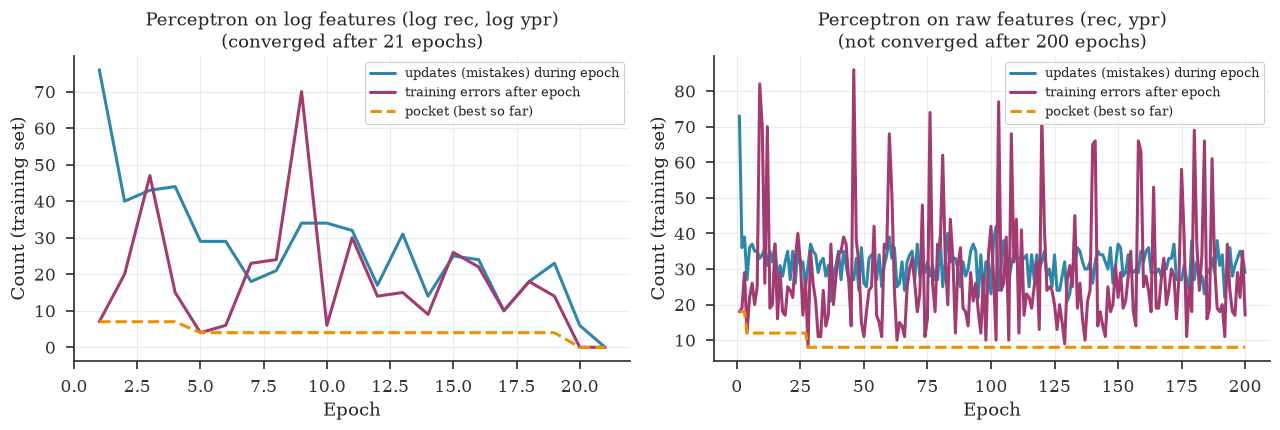

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, p) in zip(axes, perceptron_results.items()):
    epochs = np.arange(1, p.n_epochs_ + 1)
    ax.plot(epochs, p.updates_per_epoch_, label="updates (mistakes) during epoch")
    ax.plot(epochs, p.train_errors_per_epoch_, label="training errors after epoch")
    ax.plot(epochs, np.minimum.accumulate(p.train_errors_per_epoch_), ls="--", label="pocket (best so far)")
    status = f"converged after {p.n_epochs_} epochs" if p.converged_ else f"not converged after {p.n_epochs_} epochs"
    ax.set(xlabel="Epoch", ylabel="Count (training set)", title=f"Perceptron on {name}\n({status})")
    ax.legend(fontsize=9)
plt.show()

**Interpretation.** With log features the training set is linearly separable (certified by the LP), so the
convergence theorem applies and the perceptron stops after a finite number of epochs with zero training errors. With
raw features the LP is infeasible: no line separates the classes, the perceptron keeps making mistakes in every epoch,
and the final weights depend on where training happened to stop. The pocket and averaged weights are the standard
remedies; logistic regression (a smooth, convex loss) is usually the better tool. The next part removes the need to
hand-engineer the log transform by letting a hidden layer learn the curved boundary.

### Part 2: A multi-layer perceptron from scratch

**Design.** `MLPFromScratch(hidden_sizes, activation, task, optimizer, learning_rate, batch_size, max_epochs, l2,
patience, random_state)` with `fit(X, y, X_val=None, y_val=None)`, `predict`, `predict_proba`, `decision_function`.
Shapes: $X$ is $(m,d)$; `W[l]` is $(n_{l-1}, n_l)$; `b[l]` is $(1, n_l)$; the network output is $(m,1)$ and labels are
reshaped to $(m,1)$ before any arithmetic. The implementation provides:

- He initialisation for ReLU layers, Glorot uniform for tanh/sigmoid layers and the linear output layer;
- binary cross-entropy computed from logits (`softplus(z) - y z`), and $\tfrac{1}{2m}$ squared error for regression;
- output error $(\hat{y}-y)/m$, so every gradient is a batch average; optional L2 penalty on weights;
- mini-batch SGD with momentum, or Adam {cite}`kingma2014adam`;
- per-epoch training and validation loss, and early stopping that restores the best-validation weights.

It does **not** implement gradient clipping, dropout or batch normalisation.

In [7]:
import copy

import numpy as np


def sigmoid(z):
    # Numerically stable logistic function (no clipping needed).
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


ACTIVATIONS = {
    # name: (f(z), f'(z) expressed in terms of z)
    "relu": (lambda z: np.maximum(z, 0.0), lambda z: (z > 0).astype(float)),
    "tanh": (np.tanh, lambda z: 1.0 - np.tanh(z) ** 2),
    "sigmoid": (sigmoid, lambda z: sigmoid(z) * (1.0 - sigmoid(z))),
}


class MLPFromScratch:
    """Fully connected network with one output unit, trained by backpropagation.

    task="classification": sigmoid output, binary cross-entropy loss
        L = mean(-y log p - (1 - y) log(1 - p)), computed from logits.
    task="regression": identity output, loss L = (1 / 2m) * sum (yhat - y)^2.
    Both losses are averaged over the m examples in a batch, so the output
    error is delta = (yhat - y) / m in both cases. An optional L2 penalty
    (l2 / 2) * sum ||W||^2 is added (biases are not penalised).
    """

    def __init__(self, hidden_sizes=(32, 16), activation="relu", task="classification",
                 optimizer="adam", learning_rate=1e-3, momentum=0.9, batch_size=32,
                 max_epochs=300, l2=0.0, patience=None, random_state=0):
        if activation not in ACTIVATIONS:
            raise ValueError(f"Unsupported activation: {activation}")
        if task not in ("classification", "regression"):
            raise ValueError(f"Unsupported task: {task}")
        if optimizer not in ("sgd", "adam"):
            raise ValueError(f"Unsupported optimizer: {optimizer}")
        self.hidden_sizes = tuple(hidden_sizes)
        self.activation = activation
        self.task = task
        self.optimizer = optimizer
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.l2 = l2
        self.patience = patience
        self.random_state = random_state
        self._act, self._act_grad = ACTIVATIONS[activation]

    # ----- parameters ---------------------------------------------------
    def init_params(self, n_features):
        rng = np.random.default_rng(self.random_state)
        sizes = [n_features, *self.hidden_sizes, 1]
        self.W, self.b = [], []
        for layer, (fan_in, fan_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            feeds_relu = self.activation == "relu" and layer < len(sizes) - 2
            if feeds_relu:   # He et al. (2015): Var(W) = 2 / fan_in for ReLU layers
                W = rng.normal(0.0, np.sqrt(2.0 / fan_in), size=(fan_in, fan_out))
            else:            # Glorot & Bengio (2010) uniform for tanh/sigmoid/linear output
                limit = np.sqrt(6.0 / (fan_in + fan_out))
                W = rng.uniform(-limit, limit, size=(fan_in, fan_out))
            self.W.append(W)
            self.b.append(np.zeros((1, fan_out)))
        return self

    @property
    def params(self):
        return self.W + self.b

    @property
    def n_params(self):
        return int(sum(p.size for p in self.params))

    # ----- forward / loss / backward -----------------------------------
    def _forward(self, X):
        A, Z = [X], []
        a = X
        n_layers = len(self.W)
        for layer in range(n_layers):
            z = a @ self.W[layer] + self.b[layer]
            Z.append(z)
            a = self._act(z) if layer < n_layers - 1 else z  # output layer returns the raw score
            A.append(a)
        return Z, A

    def _column(self, y):
        return np.asarray(y, dtype=float).reshape(-1, 1)   # (m,) -> (m, 1): avoids (m, m) broadcasting

    def data_loss(self, X, y):
        y = self._column(y)
        score = self._forward(X)[0][-1]
        assert score.shape == y.shape, (score.shape, y.shape)
        if self.task == "classification":
            # BCE from logits: softplus(z) - y z  ==  -y log sigmoid(z) - (1-y) log(1 - sigmoid(z))
            return float(np.mean(np.logaddexp(0.0, score) - y * score))
        return float(0.5 * np.mean((score - y) ** 2))

    def loss(self, X, y):
        penalty = 0.5 * self.l2 * sum(float(np.sum(W ** 2)) for W in self.W)
        return self.data_loss(X, y) + penalty

    def gradients(self, X, y):
        y = self._column(y)
        m = X.shape[0]
        Z, A = self._forward(X)
        out = sigmoid(Z[-1]) if self.task == "classification" else Z[-1]
        delta = (out - y) / m                     # dL/dz_out for BCE+sigmoid and for (1/2m) SSE
        grad_W = [None] * len(self.W)
        grad_b = [None] * len(self.b)
        for layer in reversed(range(len(self.W))):
            grad_W[layer] = A[layer].T @ delta + self.l2 * self.W[layer]
            grad_b[layer] = delta.sum(axis=0, keepdims=True)
            if layer > 0:
                delta = (delta @ self.W[layer].T) * self._act_grad(Z[layer - 1])
        return grad_W + grad_b                    # same order as self.params

    # ----- training ------------------------------------------------------
    def _step(self, grads):
        self._t += 1
        for i, (p, g) in enumerate(zip(self.params, grads)):
            if self.optimizer == "sgd":
                self._m[i] = self.momentum * self._m[i] - self.learning_rate * g
                p += self._m[i]
            else:  # Adam (Kingma & Ba, 2015) with default beta1, beta2, eps
                b1, b2, eps = 0.9, 0.999, 1e-8
                self._m[i] = b1 * self._m[i] + (1 - b1) * g
                self._v[i] = b2 * self._v[i] + (1 - b2) * g * g
                m_hat = self._m[i] / (1 - b1 ** self._t)
                v_hat = self._v[i] / (1 - b2 ** self._t)
                p -= self.learning_rate * m_hat / (np.sqrt(v_hat) + eps)

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.init_params(X.shape[1])
        rng = np.random.default_rng(self.random_state)
        self._m = [np.zeros_like(p) for p in self.params]
        self._v = [np.zeros_like(p) for p in self.params]
        self._t = 0
        m = X.shape[0]
        batch = m if self.batch_size is None else self.batch_size
        self.history_ = {"train_loss": [], "val_loss": []}
        best, best_val, wait = None, np.inf, 0
        for epoch in range(self.max_epochs):
            order = rng.permutation(m)
            for start in range(0, m, batch):
                idx = order[start:start + batch]
                self._step(self.gradients(X[idx], y[idx]))
            self.history_["train_loss"].append(self.data_loss(X, y))
            if X_val is not None:
                val = self.data_loss(np.asarray(X_val, dtype=float), y_val)
                self.history_["val_loss"].append(val)
                if self.patience is not None:
                    if val < best_val - 1e-6:
                        best_val, wait = val, 0
                        best = (copy.deepcopy(self.W), copy.deepcopy(self.b), epoch)
                    else:
                        wait += 1
                        if wait >= self.patience:
                            break
        self.n_epochs_ = epoch + 1
        self.best_epoch_ = self.n_epochs_ - 1
        if best is not None:
            self.W, self.b, self.best_epoch_ = best
        return self

    def decision_function(self, X):
        return self._forward(np.asarray(X, dtype=float))[0][-1].ravel()

    def predict_proba(self, X):
        if self.task != "classification":
            raise ValueError("predict_proba is only defined for classification")
        p = sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])

    def predict(self, X):
        score = self.decision_function(X)
        if self.task == "classification":
            return (score > 0).astype(int)
        return score


def gradient_check(model, X, y, eps=1e-5):
    """Max relative error between backprop and central differences over all parameters."""
    analytic = model.gradients(X, y)
    worst = 0.0
    for p, g in zip(model.params, analytic):
        for idx in np.ndindex(p.shape):
            old = p[idx]
            p[idx] = old + eps
            plus = model.loss(X, y)
            p[idx] = old - eps
            minus = model.loss(X, y)
            p[idx] = old
            numeric = (plus - minus) / (2 * eps)
            rel = abs(g[idx] - numeric) / max(1e-8, abs(g[idx]) + abs(numeric))
            worst = max(worst, rel)
    return worst

### Unit checks

1. **Gradient check.** Compare backpropagation with central differences
   $\big(L(\theta+\varepsilon)-L(\theta-\varepsilon)\big)/2\varepsilon$ for *every* parameter, using relative error
   $|a-n|/\max(10^{-8}, |a|+|n|)$, in float64, with an L2 penalty switched on, for all three activations and both tasks.
   Errors around $10^{-7}$ or below indicate correct gradients; a missing $1/m$ or a broadcasting bug gives errors of
   order 1.
2. **Shape bug demonstration.** The loss written as `mean(y * log(p) + ...)` with `y` of shape $(m,)$ and `p` of shape
   $(m,1)$ silently produces an $(m,m)$ matrix.

In [8]:
rng = np.random.default_rng(0)
X_gc = rng.normal(size=(20, 5))
targets_gc = {"classification": (rng.random(20) > 0.5).astype(float), "regression": rng.normal(size=20)}
rows = []
for activation in ["relu", "tanh", "sigmoid"]:
    for task, y_gc in targets_gc.items():
        net = MLPFromScratch(hidden_sizes=(6, 4), activation=activation, task=task, l2=0.01,
                             random_state=1).init_params(X_gc.shape[1])
        rows.append({"activation": activation, "task": task, "parameters": net.n_params,
                     "max relative error": gradient_check(net, X_gc, y_gc)})
gc_table = pd.DataFrame(rows)
display(gc_table.style.format({"max relative error": "{:.2e}"}))
print(f"Largest relative error over all checks: {gc_table['max relative error'].max():.2e}")
assert gc_table["max relative error"].max() < 1e-6

# The broadcasting bug, on a near-perfect predictor
y_demo = np.array([1, 0, 1, 1, 0], dtype=float)                 # shape (5,)
p_demo = np.where(y_demo == 1, 0.99, 0.01).reshape(-1, 1)       # shape (5, 1), almost always right
buggy_terms = y_demo * np.log(p_demo) + (1 - y_demo) * np.log(1 - p_demo)
correct_terms = y_demo.reshape(-1, 1) * np.log(p_demo) + (1 - y_demo.reshape(-1, 1)) * np.log(1 - p_demo)
print(f"\nBuggy loss  : terms shape {buggy_terms.shape}, loss = {-buggy_terms.mean():.4f}")
print(f"Correct loss: terms shape {correct_terms.shape}, loss = {-correct_terms.mean():.4f}")
print(f"Constant 0.5 predictor: loss = {np.log(2):.4f}")

,activation,task,parameters,max relative error
0,relu,classification,69,7.01e-09
1,relu,regression,69,6.45e-09
2,tanh,classification,69,1.12e-09
3,tanh,regression,69,9.14e-08
4,sigmoid,classification,69,1.26e-08
5,sigmoid,regression,69,5.98e-09


Largest relative error over all checks: 9.14e-08

Buggy loss  : terms shape (5, 5), loss = 2.2157
Correct loss: terms shape (5, 1), loss = 0.0101
Constant 0.5 predictor: loss = 0.6931


3. **Unit tests** (plain `assert`s, executed below): output shapes; He/Glorot initialisation scales; training loss
   decreases; and **XOR**. XOR is the classic example of data that is **not** linearly separable: no line puts
   $(0,1),(1,0)$ on one side and $(0,0),(1,1)$ on the other, so any linear classifier gets at least one of the four
   points wrong. A single hidden layer solves it.

In [9]:
from sklearn.linear_model import LogisticRegression


def test_shapes():
    X = np.random.default_rng(1).normal(size=(32, 8))
    y = (X[:, 0] > 0).astype(int)
    net = MLPFromScratch(hidden_sizes=(10, 5), max_epochs=5, random_state=0).fit(X, y)
    assert [W.shape for W in net.W] == [(8, 10), (10, 5), (5, 1)]
    assert net.predict(X).shape == (32,) and net.predict_proba(X).shape == (32, 2)
    reg = MLPFromScratch(hidden_sizes=(4,), task="regression", max_epochs=5).fit(X, X[:, 1])
    assert reg.predict(X).shape == (32,)


def test_initialisation_scales():
    he = MLPFromScratch(hidden_sizes=(2000,), activation="relu", random_state=0).init_params(500)
    gl = MLPFromScratch(hidden_sizes=(2000,), activation="tanh", random_state=0).init_params(500)
    assert abs(he.W[0].std() / np.sqrt(2 / 500) - 1) < 0.01          # He: std = sqrt(2 / fan_in)
    assert abs(gl.W[0].std() / np.sqrt(2 / (500 + 2000)) - 1) < 0.01 # Glorot: std = sqrt(2 / (fan_in + fan_out))


def test_loss_decreases():
    X = np.random.default_rng(2).normal(size=(200, 3))
    y = (X[:, 0] * X[:, 1] > 0).astype(int)
    net = MLPFromScratch(hidden_sizes=(16,), max_epochs=50, learning_rate=1e-2, random_state=0).fit(X, y)
    assert net.history_["train_loss"][-1] < 0.5 * net.history_["train_loss"][0]


X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])


def test_xor():
    linear_acc = LogisticRegression().fit(X_xor, y_xor).score(X_xor, y_xor)
    assert linear_acc <= 0.75, "a linear model cannot fit XOR"
    for seed in range(5):
        net = MLPFromScratch(hidden_sizes=(4,), activation="tanh", optimizer="sgd", learning_rate=0.5,
                             batch_size=None, max_epochs=2000, random_state=seed).fit(X_xor, y_xor)
        assert (net.predict(X_xor) == y_xor).all(), f"seed {seed} failed"
    return linear_acc, net


for unit_test in [test_shapes, test_initialisation_scales, test_loss_decreases, test_xor]:
    result = unit_test()
    print(f"PASS {unit_test.__name__}")
linear_acc, xor_net = result
print(f"\nXOR: logistic regression training accuracy = {linear_acc:.2f}; "
      f"MLP(4 tanh units) predictions = {xor_net.predict(X_xor).tolist()} (targets {y_xor.tolist()}), "
      f"loss {xor_net.history_['train_loss'][0]:.4f} -> {xor_net.history_['train_loss'][-1]:.6f}")

PASS test_shapes
PASS test_initialisation_scales
PASS test_loss_decreases


PASS test_xor

XOR: logistic regression training accuracy = 0.50; MLP(4 tanh units) predictions = [0, 1, 1, 0] (targets [0, 1, 1, 0]), loss 0.7270 -> 0.000198


### Application: learning the curved 1,000-yard boundary from raw inputs

The perceptron could not separate 1,000-yard seasons using raw receptions and yards per reception. Here the
from-scratch MLP (one hidden layer of 16 tanh units, Adam, early stopping on the validation split) is trained on the
same raw, standardised inputs and compared with logistic regression on the same inputs, and with the majority-class
baseline. The scaler is fit on the training split only.

In [10]:
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score

scaler_1k = StandardScaler().fit(raw_xy[idx_tr])
F_tr, F_va, F_te = (scaler_1k.transform(raw_xy[i]) for i in (idx_tr, idx_va, idx_te))
y_tr1k, y_va1k, y_te1k = y1k[idx_tr], y1k[idx_va], y1k[idx_te]

scratch_1k = MLPFromScratch(hidden_sizes=(16,), activation="tanh", learning_rate=1e-2, batch_size=32,
                            max_epochs=1000, patience=50, random_state=SEED).fit(F_tr, y_tr1k, F_va, y_va1k)
logit_1k = LogisticRegression().fit(F_tr, y_tr1k)
prior = y_tr1k.mean()

rows = []
for name, proba in [("majority class (prior)", np.full(len(y_te1k), prior)),
                    ("logistic regression", logit_1k.predict_proba(F_te)[:, 1]),
                    ("from-scratch MLP (16 tanh)", scratch_1k.predict_proba(F_te)[:, 1])]:
    rows.append({"model": name, "test accuracy": accuracy_score(y_te1k, proba > 0.5),
                 "test log loss": log_loss(y_te1k, proba),
                 "test errors": int(np.sum((proba > 0.5) != y_te1k))})
display(pd.DataFrame(rows).set_index("model").style.format(
    {"test accuracy": "{:.4f}", "test log loss": "{:.4f}"}))
print(f"MLP trained {scratch_1k.n_epochs_} epochs; best validation loss at epoch {scratch_1k.best_epoch_ + 1}; "
      f"{scratch_1k.n_params} parameters. Test set: {len(y_te1k)} seasons, {y_te1k.sum()} positives.")

,test accuracy,test log loss,test errors
model,,,
majority class (prior),0.8524,0.4185,58
logistic regression,0.9796,0.0650,8
from-scratch MLP (16 tanh),0.9975,0.0071,1


MLP trained 708 epochs; best validation loss at epoch 658; 65 parameters. Test set: 393 seasons, 58 positives.


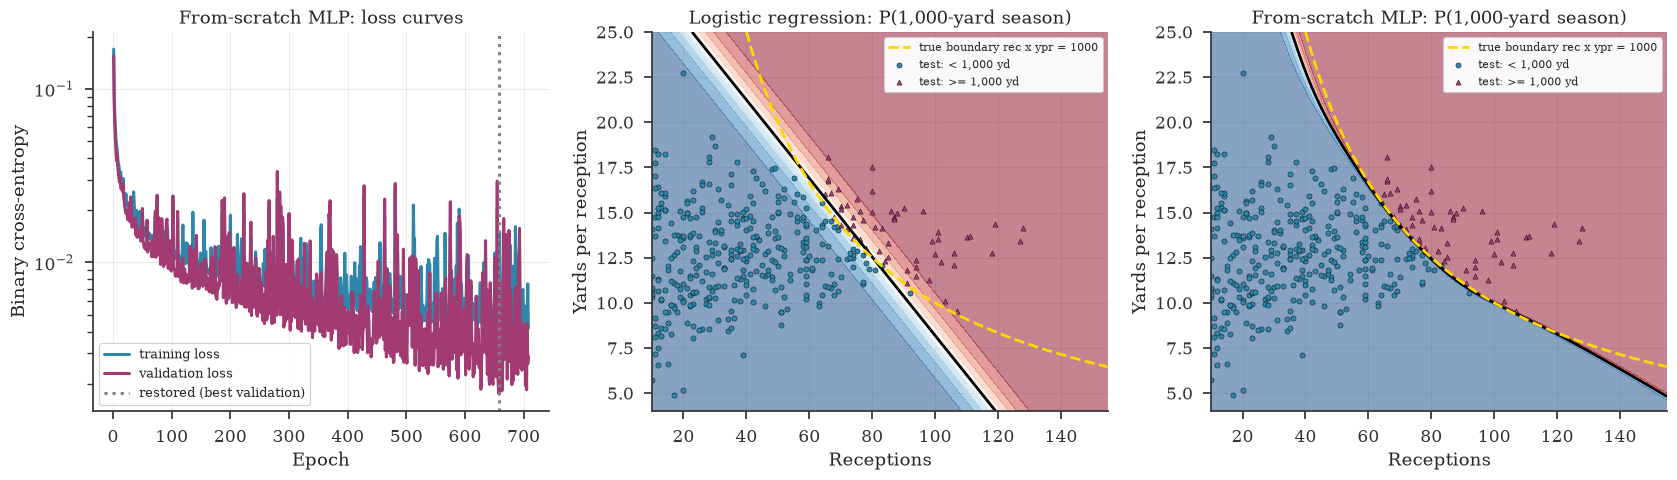

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
h = scratch_1k.history_
ax.plot(np.arange(1, len(h["train_loss"]) + 1), h["train_loss"], label="training loss")
ax.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation loss")
ax.axvline(scratch_1k.best_epoch_ + 1, color="grey", ls=":", label="restored (best validation)")
ax.set(xlabel="Epoch", ylabel="Binary cross-entropy", yscale="log", title="From-scratch MLP: loss curves")
ax.legend(fontsize=9)

rec_grid, ypr_grid = np.meshgrid(np.linspace(10, 155, 300), np.linspace(4, 25, 300))
grid = scaler_1k.transform(np.column_stack([rec_grid.ravel(), ypr_grid.ravel()]))
test_pts = raw_xy[idx_te]
curve_rec = np.linspace(40, 155, 200)
for ax, (name, model) in zip(axes[1:], [("Logistic regression", logit_1k), ("From-scratch MLP", scratch_1k)]):
    proba = model.predict_proba(grid)[:, 1].reshape(rec_grid.shape)
    ax.contourf(rec_grid, ypr_grid, proba, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.5)
    ax.contour(rec_grid, ypr_grid, proba, levels=[0.5], colors="black", linewidths=2)
    ax.plot(curve_rec, 1000 / curve_rec, color="gold", lw=2, ls="--", label="true boundary rec x ypr = 1000")
    for cls, marker, label in [(0, "o", "< 1,000 yd"), (1, "^", ">= 1,000 yd")]:
        m = y_te1k == cls
        ax.scatter(test_pts[m, 0], test_pts[m, 1], s=14, marker=marker, edgecolor="k", lw=0.3,
                   label=f"test: {label}")
    ax.set(xlim=(10, 155), ylim=(4, 25), xlabel="Receptions", ylabel="Yards per reception",
           title=f"{name}: P(1,000-yard season)")
    ax.legend(fontsize=8, loc="upper right")
plt.show()

**Interpretation.** Training and validation loss both fall by more than an order of magnitude (with mini-batch noise),
and the weights from the best validation epoch are kept. Logistic regression's boundary (black line, middle panel) is
straight, so it cuts across the true hyperbola (gold); the MLP's boundary bends to follow the hyperbola wherever there
are data, and departs from it only outside the data (low yards per reception with very many receptions), where nothing
constrains it. On the 393 test seasons that is 8 errors for logistic regression against 1 for the MLP. This is a case
where the hidden layer earns its keep: the target is a known non-linear function of the inputs and there is no label
noise.

## Applications (Experiments)

### Part 3: scikit-learn on the main task — will a receiver reach a 1,000-yard pace next season?

Every model below is a `Pipeline` whose `StandardScaler` is fit on the training seasons only. Classification metrics:
accuracy at threshold 0.5, log loss (lower is better; it rewards calibrated probabilities), ROC AUC (ranking quality;
0.5 = no skill) and Brier score (mean squared error of the probability). Baselines: the majority class (predict the
training prevalence for everyone), a *persistence rule* (predict "yes" if the player was already on a 1,000-yard pace in
season $t$), and logistic regression. The MLP is trained with five random seeds to show seed-to-seed variation.

In [12]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import brier_score_loss, mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline

N_SEEDS = 5


def paired_bootstrap_ci(y, pred_a, pred_b, metric, n_boot=2000, seed=SEED):
    """95% percentile interval of metric(a) - metric(b) over test rows resampled with replacement."""
    rng = np.random.default_rng(seed)
    y, pred_a, pred_b = map(np.asarray, (y, pred_a, pred_b))
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2 and metric is roc_auc_score:
            continue
        diffs.append(metric(y[idx], pred_a[idx]) - metric(y[idx], pred_b[idx]))
    return metric(y, pred_a) - metric(y, pred_b), np.percentile(diffs, [2.5, 97.5])


def classification_metrics(y, proba):
    return {"accuracy": accuracy_score(y, proba > 0.5), "log loss": log_loss(y, proba, labels=[0, 1]),
            "ROC AUC": roc_auc_score(y, proba) if np.ptp(proba) > 0 else 0.5,
            "Brier": brier_score_loss(y, proba)}


def evaluate_classifier(name, val_proba, test_proba):
    row = {"model": name}
    for split_name, y, proba in [("val", y_val, val_proba), ("test", y_test, test_proba)]:
        row.update({f"{split_name} {k}": v for k, v in classification_metrics(y, proba).items()})
    return row


rows = []
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
rows.append(evaluate_classifier("majority class (prior)", dummy.predict_proba(X_val)[:, 1],
                                dummy.predict_proba(X_test)[:, 1]))
yards_col = FEATURES.index("yards_pg")
rows.append(evaluate_classifier("persistence rule (pace in season t)",
                                (X_val[:, yards_col] >= THRESHOLD).astype(float),
                                (X_test[:, yards_col] >= THRESHOLD).astype(float)))
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
rows.append(evaluate_classifier("logistic regression", logreg.predict_proba(X_val)[:, 1],
                                logreg.predict_proba(X_test)[:, 1]))

mlp_rows, n_iters = [], []
for seed in range(N_SEEDS):
    mlp = make_pipeline(StandardScaler(),
                        MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", alpha=1e-4,
                                      max_iter=2000, random_state=seed)).fit(X_train, y_train)
    n_iters.append(mlp[-1].n_iter_)
    mlp_rows.append(evaluate_classifier("MLP", mlp.predict_proba(X_val)[:, 1], mlp.predict_proba(X_test)[:, 1]))
mlp_df = pd.DataFrame(mlp_rows).drop(columns="model")
rows.append({"model": f"MLP (32, 16), alpha=1e-4, mean of {N_SEEDS} seeds", **mlp_df.mean().to_dict()})
rows.append({"model": f"  ... standard deviation over seeds", **mlp_df.std().to_dict()})
part3_cls = pd.DataFrame(rows).set_index("model")
display(part3_cls.style.format("{:.3f}"))
print(f"MLP epochs used per seed: {n_iters} (max_iter=2000, so every run stopped on its own tolerance criterion)")
print(f"MLP (seed {N_SEEDS - 1}) training accuracy vs test accuracy: "
      f"{mlp.score(X_train, y_train):.3f} vs {mlp.score(X_test, y_test):.3f}")

,val accuracy,val log loss,val ROC AUC,val Brier,test accuracy,test log loss,test ROC AUC,test Brier
model,,,,,,,,
majority class (prior),0.755,0.559,0.500,0.186,0.773,0.540,0.500,0.177
persistence rule (pace in season t),0.875,4.505,0.828,0.125,0.801,7.175,0.763,0.199
logistic regression,0.870,0.290,0.941,0.088,0.787,0.423,0.830,0.137
"MLP (32, 16), alpha=1e-4, mean of 5 seeds",0.795,1.164,0.801,0.179,0.749,1.965,0.709,0.227
... standard deviation over seeds,0.012,0.300,0.026,0.011,0.021,0.264,0.018,0.013


MLP epochs used per seed: [1692, 1458, 1693, 1591, 1441] (max_iter=2000, so every run stopped on its own tolerance criterion)
MLP (seed 4) training accuracy vs test accuracy: 0.991 vs 0.727


**Regression version.** Target: next-season receiving yards per game. Baselines: the training mean, persistence (predict
this season's yards per game) and linear regression. The MLP is wrapped in `TransformedTargetRegressor` so that it is
trained on a standardised target (raw yards per game would otherwise dominate the loss scale and slow Adam down). Its
L2 strength `alpha` is chosen by validation-season RMSE from a small grid before the final fits; because of that
selection, the MLP's validation-column numbers are slightly optimistic, and only its test column is an unbiased
comparison.

MLPRegressor validation RMSE by alpha (mean of 3 seeds): {0.0001: 20.717, 0.01: 20.03, 1.0: 16.022, 10.0: 15.414, 100.0: 25.034} -> selected alpha = 10.0


,val MAE,val RMSE,val R2,test MAE,test RMSE,test R2
model,,,,,,
training mean,21.096,24.999,-0.015,19.537,23.144,-0.028
persistence (yards/game in season t),13.493,16.208,0.573,13.967,17.506,0.412
linear regression,13.001,15.661,0.602,12.937,16.003,0.509
"MLP (32, 16), alpha=10 (chosen on validation), scaled target, mean of 5 seeds",12.687,15.437,0.613,12.877,15.766,0.523
... standard deviation over seeds,0.042,0.046,0.002,0.027,0.032,0.002


MLPRegressor epochs used per seed: [283, 258, 254, 243, 231] (max_iter=10000)


Test RMSE, MLP (5-seed average prediction) minus linear regression: -0.240 (paired bootstrap 95% interval -0.767 to 0.213; negative favours the MLP)


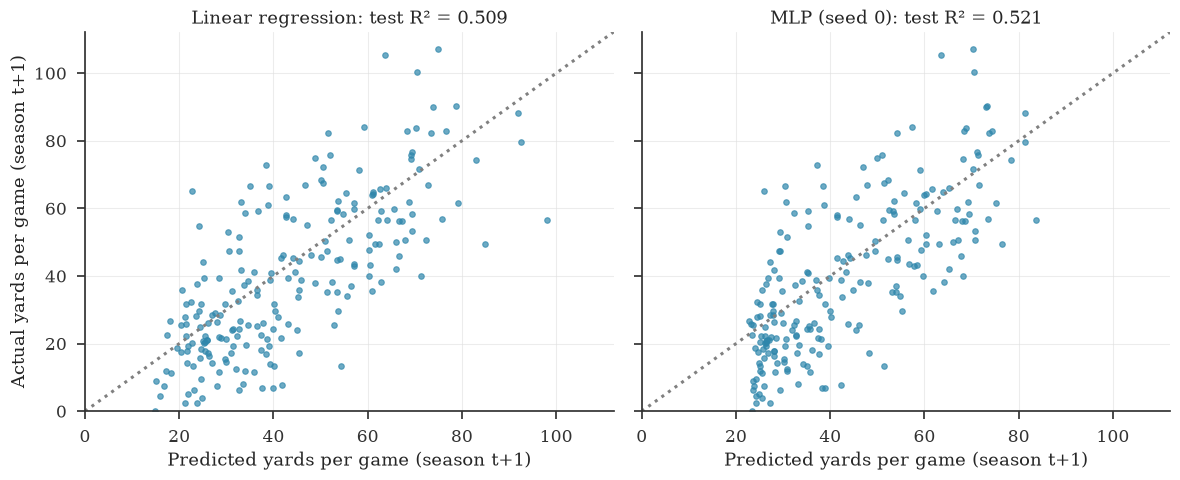

In [13]:
def regression_metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred), "RMSE": root_mean_squared_error(y, pred), "R2": r2_score(y, pred)}


def evaluate_regressor(name, val_pred, test_pred):
    row = {"model": name}
    for split_name, y, pred in [("val", r_val, val_pred), ("test", r_test, test_pred)]:
        row.update({f"{split_name} {k}": v for k, v in regression_metrics(y, pred).items()})
    return row


rows = []
dmean = DummyRegressor(strategy="mean").fit(X_train, r_train)
rows.append(evaluate_regressor("training mean", dmean.predict(X_val), dmean.predict(X_test)))
rows.append(evaluate_regressor("persistence (yards/game in season t)", X_val[:, yards_col], X_test[:, yards_col]))
linreg = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, r_train)
rows.append(evaluate_regressor("linear regression", linreg.predict(X_val), linreg.predict(X_test)))

REG_MAX_ITER = 10_000


def mlp_regressor(alpha, seed):
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(),
                                MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", alpha=alpha,
                                             max_iter=REG_MAX_ITER, random_state=seed)),
        transformer=StandardScaler())


# Choose the L2 strength on the validation seasons only (3 seeds per value); the test seasons are not used here.
alpha_rows = []
for alpha in [1e-4, 1e-2, 1.0, 10.0, 100.0]:
    for seed in range(3):
        m = mlp_regressor(alpha, seed).fit(X_train, r_train)
        assert m.regressor_[-1].n_iter_ < REG_MAX_ITER
        alpha_rows.append({"alpha": alpha, "seed": seed,
                           "val RMSE": root_mean_squared_error(r_val, m.predict(X_val))})
reg_alpha_table = pd.DataFrame(alpha_rows).groupby("alpha")["val RMSE"].mean()
best_reg_alpha = reg_alpha_table.idxmin()
print("MLPRegressor validation RMSE by alpha (mean of 3 seeds):",
      {a: round(v, 3) for a, v in reg_alpha_table.items()}, f"-> selected alpha = {best_reg_alpha}")

reg_rows, reg_iters, reg_test_preds = [], [], []
for seed in range(N_SEEDS):
    mlp_reg = mlp_regressor(best_reg_alpha, seed).fit(X_train, r_train)
    reg_iters.append(mlp_reg.regressor_[-1].n_iter_)
    reg_test_preds.append(mlp_reg.predict(X_test))
    reg_rows.append(evaluate_regressor("MLP", mlp_reg.predict(X_val), reg_test_preds[-1]))
assert max(reg_iters) < REG_MAX_ITER
reg_df = pd.DataFrame(reg_rows).drop(columns="model")
rows.append({"model": f"MLP (32, 16), alpha={best_reg_alpha:g} (chosen on validation), scaled target, "
                      f"mean of {N_SEEDS} seeds", **reg_df.mean().to_dict()})
rows.append({"model": "  ... standard deviation over seeds", **reg_df.std().to_dict()})
part3_reg = pd.DataFrame(rows).set_index("model")
display(part3_reg.style.format("{:.3f}"))
print(f"MLPRegressor epochs used per seed: {reg_iters} (max_iter={REG_MAX_ITER})")
mlp_reg_avg = np.mean(reg_test_preds, axis=0)
diff, (lo, hi) = paired_bootstrap_ci(r_test, mlp_reg_avg, linreg.predict(X_test), root_mean_squared_error)
print(f"Test RMSE, MLP ({N_SEEDS}-seed average prediction) minus linear regression: {diff:.3f} "
      f"(paired bootstrap 95% interval {lo:.3f} to {hi:.3f}; negative favours the MLP)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
lim = [0, r_test.max() + 5]
for ax, (name, pred) in zip(axes, [("Linear regression", linreg.predict(X_test)),
                                   ("MLP (seed 0)", reg_test_preds[0])]):
    ax.scatter(pred, r_test, s=16, alpha=0.7)
    ax.plot(lim, lim, color="grey", ls=":")
    ax.set(xlim=lim, ylim=lim, xlabel="Predicted yards per game (season t+1)",
           title=f"{name}: test R² = {r2_score(r_test, pred):.3f}")
axes[0].set_ylabel("Actual yards per game (season t+1)")
plt.show()

**Interpretation.**

- **There is real signal.** Logistic regression beats the majority class on every test metric (log loss 0.423 vs 0.540,
  ROC AUC 0.830 vs 0.500), and linear regression explains about half of the test variance in next-season yards per game
  ($R^2$ = 0.509, against 0.412 for persistence and −0.028 for the training mean).
- **Accuracy alone misleads.** The persistence rule has the highest test accuracy in the table (0.801), but because it
  outputs hard 0/1 "probabilities" its log loss (7.175) is far worse than any probabilistic model's.
- **An untuned MLP overfits badly.** The (32, 16) network with scikit-learn's default L2 strength (`alpha=1e-4`) and no
  early stopping fits the training seasons almost perfectly (training accuracy 0.991 for the last seed) but is *worse
  than the majority class* on test accuracy (0.749 vs 0.773) and log loss (1.965 vs 0.540). Its ranking is still better
  than chance (ROC AUC 0.709), but its probabilities are over-confident.
- **A regularised MLP matches linear regression.** For the regression MLP, `alpha` was chosen on the validation seasons
  (validation RMSE 15.414 at `alpha` = 10, against 20.717 at the default 1e-4). With it, the MLP's test $R^2$ is 0.523
  against 0.509 for linear regression (test MAE 12.877 vs 12.937). The paired bootstrap interval for the RMSE difference
  (−0.767 to 0.213 yards per game) for the MLP's 5-seed average prediction includes zero, so this small edge is not distinguishable from sampling noise on 216
  test rows.

With about 900 training rows and 14 strongly correlated features, the learnable relationship is close to linear and
extra capacity mostly adds variance. Part 4 controls it with early stopping, and Part 5 with validation-set tuning.

Note the shrinkage in Figure 4: with alpha = 10 the network never predicts much below the low twenties, while actual values reach zero. A strong L2 penalty pulls extreme predictions toward the mean; that is part of the price of its lower variance.


### Part 4: The same network in scikit-learn, Keras 3, PyTorch and NumPy

All four implementations use **one protocol** on the main classification task: inputs standardised with a scaler fit
on the training seasons; architecture 14 → 32 → 16 → 1 with ReLU and a sigmoid/logit output; binary cross-entropy;
Adam with learning rate $10^{-3}$; batch size 32; no weight decay; at most 500 epochs; early stopping with patience 20 on
validation log loss, restoring the best weights. Each is trained with five seeds.

What legitimately differs: default weight initialisation (scikit-learn: Glorot-style uniform; Keras: Glorot uniform;
PyTorch: Kaiming-uniform with $a=\sqrt5$; ours: He normal), random-number streams for shuffling, and floating-point
precision (float32 in Keras and PyTorch, float64 in scikit-learn and NumPy). Keras runs on its PyTorch backend here, but its
layers, initialisers, optimiser and training loop are Keras' own. So we expect *similar* but not identical
results; identical numbers across frameworks would be a coincidence, not a proof of correctness. (Correctness of the
from-scratch gradients was established by the gradient check in Part 2.)

In [14]:
import keras
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.use_deterministic_algorithms(True)
print(f"Keras {keras.__version__} with backend '{keras.backend.backend()}'; PyTorch {torch.__version__}")

scaler_main = StandardScaler().fit(X_train)                       # training seasons only
Xs_train, Xs_val, Xs_test = (scaler_main.transform(X) for X in (X_train, X_val, X_test))
HIDDEN, LR, BATCH, MAX_EPOCHS, PATIENCE = (32, 16), 1e-3, 32, 500, 20


def bce(y, p):
    return log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1])


def train_sklearn(seed):
    clf = MLPClassifier(hidden_layer_sizes=HIDDEN, activation="relu", solver="adam", alpha=0.0,
                        learning_rate_init=LR, batch_size=BATCH, random_state=seed)
    hist, best, best_val, wait = {"train_loss": [], "val_loss": []}, None, np.inf, 0
    for epoch in range(MAX_EPOCHS):
        clf.partial_fit(Xs_train, y_train, classes=[0, 1])      # one pass over the shuffled training data
        hist["train_loss"].append(bce(y_train, clf.predict_proba(Xs_train)[:, 1]))
        hist["val_loss"].append(bce(y_val, clf.predict_proba(Xs_val)[:, 1]))
        if hist["val_loss"][-1] < best_val - 1e-6:
            best, best_val, wait = copy.deepcopy(clf), hist["val_loss"][-1], 0
        elif (wait := wait + 1) >= PATIENCE:
            break
    return best.predict_proba(Xs_test)[:, 1], hist


class FullTrainingLoss(keras.callbacks.Callback):
    """Record full-training-set loss at the end of each epoch (Keras' own 'loss' is a running batch mean)."""

    def on_train_begin(self, logs=None):
        self.losses = []

    def on_epoch_end(self, epoch, logs=None):
        logits = self.model(Xs_train, training=False)
        self.losses.append(bce(y_train, keras.ops.convert_to_numpy(keras.ops.sigmoid(logits)).ravel()))


def train_keras(seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([keras.Input(shape=(len(FEATURES),)),
                              keras.layers.Dense(HIDDEN[0], activation="relu"),
                              keras.layers.Dense(HIDDEN[1], activation="relu"),
                              keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                  loss=keras.losses.BinaryCrossentropy(from_logits=True))
    full_loss = FullTrainingLoss()
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    fit = model.fit(Xs_train, y_train.astype("float32"), validation_data=(Xs_val, y_val.astype("float32")),
                    epochs=MAX_EPOCHS, batch_size=BATCH, shuffle=True, verbose=0, callbacks=[full_loss, stop])
    logits = keras.ops.convert_to_numpy(model(Xs_test, training=False)).ravel()
    return 1 / (1 + np.exp(-logits)), {"train_loss": full_loss.losses, "val_loss": fit.history["val_loss"]}


def train_torch(seed):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(len(FEATURES), HIDDEN[0]), nn.ReLU(),
                          nn.Linear(HIDDEN[0], HIDDEN[1]), nn.ReLU(), nn.Linear(HIDDEN[1], 1))
    optimiser = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()
    as_t = lambda a: torch.as_tensor(np.array(a, dtype=np.float32))   # writable float32 copy
    Xt, Xv, Xte = as_t(Xs_train), as_t(Xs_val), as_t(Xs_test)
    yt, yv = as_t(y_train).reshape(-1, 1), as_t(y_val).reshape(-1, 1)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist, best, best_val, wait = {"train_loss": [], "val_loss": []}, None, np.inf, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimiser.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimiser.step()
        model.eval()
        with torch.no_grad():
            hist["train_loss"].append(loss_fn(model(Xt), yt).item())
            hist["val_loss"].append(loss_fn(model(Xv), yv).item())
        if hist["val_loss"][-1] < best_val - 1e-6:
            best, best_val, wait = copy.deepcopy(model.state_dict()), hist["val_loss"][-1], 0
        elif (wait := wait + 1) >= PATIENCE:
            break
    model.load_state_dict(best)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(Xte)).numpy().ravel(), hist


def train_scratch(seed):
    net = MLPFromScratch(hidden_sizes=HIDDEN, activation="relu", optimizer="adam", learning_rate=LR,
                         batch_size=BATCH, max_epochs=MAX_EPOCHS, patience=PATIENCE,
                         random_state=seed).fit(Xs_train, y_train, Xs_val, y_val)
    return net.predict_proba(Xs_test)[:, 1], net.history_

Keras 3.15.1 with backend 'torch'; PyTorch 2.14.1+cpu


In [15]:
trainers = {"scikit-learn (partial_fit)": train_sklearn, "Keras 3": train_keras,
            "PyTorch": train_torch, "NumPy from scratch": train_scratch}
framework_rows, framework_histories = [], {}
for name, trainer in trainers.items():
    start = time.perf_counter()
    for seed in range(N_SEEDS):
        proba, hist = trainer(seed)
        best_epoch = int(np.argmin(hist["val_loss"])) + 1
        framework_rows.append({"implementation": name, "seed": seed, "epochs run": len(hist["val_loss"]),
                               "best epoch": best_epoch, "best val log loss": min(hist["val_loss"]),
                               **{f"test {k}": v for k, v in classification_metrics(y_test, proba).items()}})
        if seed == 0:
            framework_histories[name] = hist
    print(f"{name:28s} {N_SEEDS} seeds in {time.perf_counter() - start:5.1f} s")

framework_df = pd.DataFrame(framework_rows)
summary_cols = ["best epoch", "best val log loss", "test accuracy", "test log loss", "test ROC AUC", "test Brier"]
framework_summary = framework_df.groupby("implementation", sort=False)[summary_cols].agg(["mean", "std"])
reference = part3_cls.loc[["majority class (prior)", "logistic regression"],
                          ["test accuracy", "test log loss", "test ROC AUC", "test Brier"]]
print("\nMean and standard deviation over seeds:")
display(framework_summary.style.format("{:.3f}"))
print("Baselines on the same test set (from Part 3):")
display(reference.style.format("{:.3f}"))

scikit-learn (partial_fit)   5 seeds in   3.2 s


Keras 3                      5 seeds in  30.6 s


PyTorch                      5 seeds in   6.9 s


NumPy from scratch           5 seeds in   2.1 s

Mean and standard deviation over seeds:


Baselines on the same test set (from Part 3):


,test accuracy,test log loss,test ROC AUC,test Brier
model,,,,
majority class (prior),0.773,0.540,0.500,0.177
logistic regression,0.787,0.423,0.830,0.137


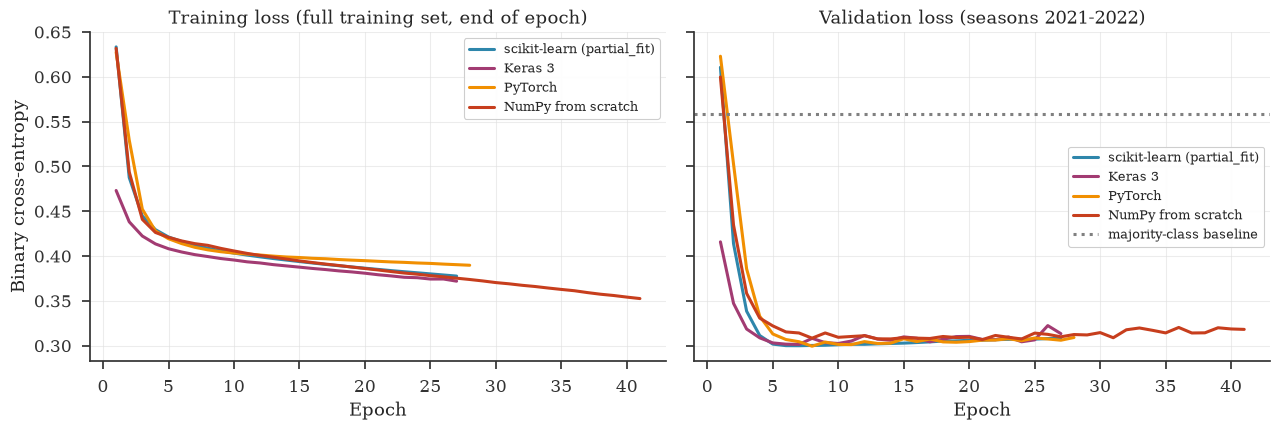

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for name, hist in framework_histories.items():
    epochs = np.arange(1, len(hist["val_loss"]) + 1)
    axes[0].plot(epochs, hist["train_loss"], label=name)
    axes[1].plot(epochs, hist["val_loss"], label=name)
axes[0].set(title="Training loss (full training set, end of epoch)", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[1].set(title="Validation loss (seasons 2021-2022)", xlabel="Epoch")
axes[1].axhline(bce(y_val, np.full(len(y_val), y_train.mean())), color="grey", ls=":",
                label="majority-class baseline")
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

**Interpretation.** In all four implementations the training loss keeps falling, while the validation loss drops to
roughly its minimum within about 5–15 epochs and then stays flat or creeps up. Further training improves the fit to
the training seasons without improving predictions for new seasons, and early stopping halts training and restores the
best-validation weights. Compare this with the untuned MLP in Part 3: the same architecture *without* early stopping
or a meaningful L2 penalty ran for well over a thousand epochs and overfitted badly. The four implementations reach
similar test metrics (see the summary table), but not identical ones: the differences between implementations are of
the same order as, and sometimes a little larger than, the seed-to-seed standard deviations — expected with different
initialisers, random streams and precisions. None beats logistic regression on test log loss or ROC AUC.

### Part 5: Hyperparameter tuning on the validation seasons

We tune `MLPClassifier` over hidden-layer sizes, activation and L2 strength (`alpha`), and — for a fair comparison —
logistic regression's inverse regularisation strength `C`, selecting by **validation log loss** (seasons 2021–2022).
Each configuration is trained on the training seasons with three seeds, and the reported validation loss is the mean.
After selection, both final models are refit on training + validation seasons and evaluated **once** on the test
seasons. A configuration counts as converged when it stops before `max_iter` (the condition under which scikit-learn
would raise `ConvergenceWarning`); this is asserted. Weakly regularised networks keep improving their training loss
slowly for thousands of epochs, so `max_iter` is set to 10,000 rather than hiding the warning.

In [17]:
import ast
from itertools import product

from joblib import Parallel, delayed

MLP_GRID = {"hidden_layer_sizes": [(8,), (32,), (32, 16), (64, 32, 16)], "activation": ["relu", "tanh"],
            "alpha": [1e-4, 1e-2, 1.0, 10.0]}
TUNE_SEEDS, MAX_ITER = range(3), 10_000   # weakly regularised nets need ~3,000+ epochs to meet tol


def fit_mlp_config(hidden, activation, alpha, seed):
    model = make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=hidden, activation=activation, alpha=alpha,
                                        max_iter=MAX_ITER, random_state=seed)).fit(X_train, y_train)
    return {"hidden_layer_sizes": str(hidden), "activation": activation, "alpha": alpha, "seed": seed,
            "n_iter": model[-1].n_iter_, "val log loss": log_loss(y_val, model.predict_proba(X_val)[:, 1]),
            "val ROC AUC": roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),
            "train log loss": log_loss(y_train, model.predict_proba(X_train)[:, 1])}


configs = list(product(MLP_GRID["hidden_layer_sizes"], MLP_GRID["activation"], MLP_GRID["alpha"], TUNE_SEEDS))
start = time.perf_counter()
tuning = pd.DataFrame(Parallel(n_jobs=min(32, os.cpu_count()))(delayed(fit_mlp_config)(*c) for c in configs))
print(f"Trained {len(configs)} MLPs in {time.perf_counter() - start:.1f} s; "
      f"max epochs used = {tuning['n_iter'].max()} < max_iter = {MAX_ITER}")
assert (tuning["n_iter"] < MAX_ITER).all(), "some configurations did not converge"

grid_summary = (tuning.groupby(["hidden_layer_sizes", "activation", "alpha"], sort=False)
                [["train log loss", "val log loss", "val ROC AUC"]].mean().sort_values("val log loss"))
print("Top 8 MLP configurations by mean validation log loss:")
display(grid_summary.head(8).style.format("{:.4f}"))

print("Ablation — best validation log loss per architecture and activation (minimised over alpha):")
display(grid_summary.reset_index().pivot_table(index="hidden_layer_sizes", columns="activation",
                                               values="val log loss", aggfunc="min")
        .reindex([str(h) for h in MLP_GRID["hidden_layer_sizes"]]).style.format("{:.4f}"))
print("Ablation — effect of L2 strength (mean over architectures and activations):")
display(grid_summary.groupby("alpha")[["train log loss", "val log loss"]].mean().style.format("{:.4f}"))

logit_rows = []
for C in [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1e3, 1e4, np.inf]:      # C = inf: no penalty at all
    lr_model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000)).fit(X_train, y_train)
    assert lr_model[-1].n_iter_[0] < 1000
    logit_rows.append({"C": C, "val log loss": log_loss(y_val, lr_model.predict_proba(X_val)[:, 1])})
logit_tuning = pd.DataFrame(logit_rows).set_index("C")
print("Logistic regression validation log loss by C (C = inf is the unpenalised fit):")
display(logit_tuning.T.style.format("{:.4f}"))

Trained 96 MLPs in 13.6 s; max epochs used = 3229 < max_iter = 10000
Top 8 MLP configurations by mean validation log loss:


Ablation — best validation log loss per architecture and activation (minimised over alpha):


activation,relu,tanh
hidden_layer_sizes,,
"(8,)",0.2985,0.2885
"(32,)",0.2995,0.2900
"(32, 16)",0.3093,0.2960
"(64, 32, 16)",0.3243,0.2931


Ablation — effect of L2 strength (mean over architectures and activations):


,train log loss,val log loss
alpha,,
0.000100,0.1444,0.8316
0.010000,0.1464,0.8250
1.000000,0.3739,0.3042
10.000000,0.4155,0.3169


Logistic regression validation log loss by C (C = inf is the unpenalised fit):


C,0.001000,0.010000,0.100000,1.000000,10.000000,100.000000,1000.000000,10000.000000,inf
val log loss,0.3940,0.3077,0.2914,0.2898,0.2887,0.2882,0.2882,0.2882,0.2882


In [18]:
best_hidden, best_act, best_alpha = grid_summary.index[0]
best_hidden = ast.literal_eval(best_hidden)      # string such as "(32,)" back to a tuple
# Most regularised C whose validation loss is within 1e-4 of the best (the curve is flat for large C).
near_best = logit_tuning["val log loss"] <= logit_tuning["val log loss"].min() + 1e-4
best_C = logit_tuning.index[near_best.to_numpy()].min()
print(f"Selected MLP: hidden_layer_sizes={best_hidden}, activation={best_act}, alpha={best_alpha}")
print(f"Selected logistic regression: C={best_C}")

X_trval, y_trval = np.vstack([X_train, X_val]), np.concatenate([y_train, y_val])
final_logit = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=1000)).fit(X_trval, y_trval)
final_mlps = [make_pipeline(StandardScaler(),
                            MLPClassifier(hidden_layer_sizes=best_hidden, activation=best_act, alpha=best_alpha,
                                          max_iter=MAX_ITER, random_state=seed)).fit(X_trval, y_trval)
              for seed in range(N_SEEDS)]
assert all(m[-1].n_iter_ < MAX_ITER for m in final_mlps)
p_logit = final_logit.predict_proba(X_test)[:, 1]
p_mlp = np.mean([m.predict_proba(X_test)[:, 1] for m in final_mlps], axis=0)   # average of 5 seeds
p_prior = np.full(len(y_test), y_trval.mean())

final_rows = [{"model": "majority class (prior)", **classification_metrics(y_test, p_prior)},
              {"model": f"logistic regression (C={best_C})", **classification_metrics(y_test, p_logit)}]
for seed, m in enumerate(final_mlps):
    final_rows.append({"model": f"tuned MLP, seed {seed}",
                       **classification_metrics(y_test, m.predict_proba(X_test)[:, 1])})
final_rows.append({"model": f"tuned MLP, average of {N_SEEDS} seeds", **classification_metrics(y_test, p_mlp)})
final_table = pd.DataFrame(final_rows).set_index("model")
print(f"\nTest seasons 2023-2024 (n = {len(y_test)}, positives = {y_test.sum()}):")
display(final_table.style.format("{:.3f}"))
for metric_name, metric in [("log loss", log_loss), ("ROC AUC", roc_auc_score)]:
    diff, (lo, hi) = paired_bootstrap_ci(y_test, p_mlp, p_logit, metric)
    print(f"Tuned MLP (5-seed average) minus logistic regression, test {metric_name}: {diff:+.3f} "
          f"(paired bootstrap 95% interval {lo:+.3f} to {hi:+.3f})")

Selected MLP: hidden_layer_sizes=(8,), activation=tanh, alpha=0.01
Selected logistic regression: C=100.0



Test seasons 2023-2024 (n = 216, positives = 49):


,accuracy,log loss,ROC AUC,Brier
model,,,,
majority class (prior),0.773,0.539,0.500,0.177
logistic regression (C=100.0),0.787,0.432,0.831,0.139
"tuned MLP, seed 0",0.792,0.446,0.817,0.143
"tuned MLP, seed 1",0.778,0.429,0.823,0.142
"tuned MLP, seed 2",0.792,0.439,0.821,0.142
"tuned MLP, seed 3",0.778,0.439,0.816,0.142
"tuned MLP, seed 4",0.787,0.419,0.829,0.136
"tuned MLP, average of 5 seeds",0.778,0.430,0.823,0.140


Tuned MLP (5-seed average) minus logistic regression, test log loss: -0.002 (paired bootstrap 95% interval -0.023 to +0.016)


Tuned MLP (5-seed average) minus logistic regression, test ROC AUC: -0.008 (paired bootstrap 95% interval -0.019 to +0.001)


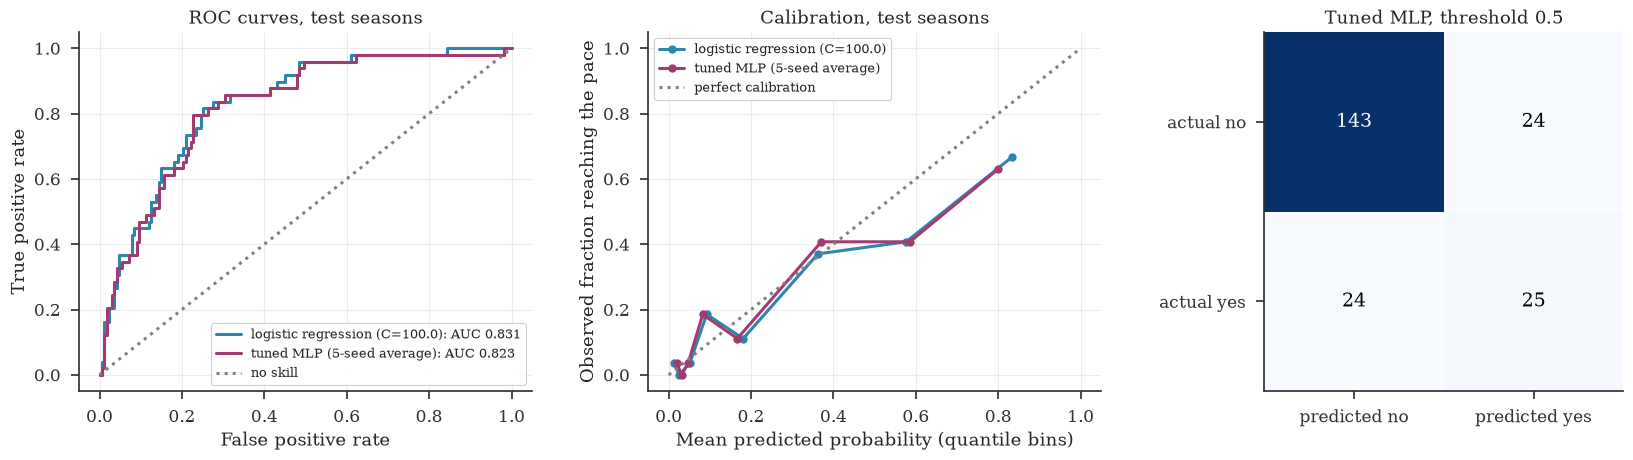

Confusion matrix (rows actual no/yes, columns predicted no/yes):
  tuned MLP          : [[143, 24], [24, 25]]
  logistic regression: [[144, 23], [23, 26]]


In [19]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, p in [(f"logistic regression (C={best_C})", p_logit), ("tuned MLP (5-seed average)", p_mlp)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name}: AUC {roc_auc_score(y_test, p):.3f}")
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    axes[1].plot(mean_pred, frac_pos, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], color="grey", ls=":", label="no skill")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves, test seasons")
axes[1].plot([0, 1], [0, 1], color="grey", ls=":", label="perfect calibration")
axes[1].set(xlabel="Mean predicted probability (quantile bins)", ylabel="Observed fraction reaching the pace",
            title="Calibration, test seasons")
for ax in axes[:2]:
    ax.legend(fontsize=9)

cm = confusion_matrix(y_test, p_mlp > 0.5)
axes[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[2].text(j, i, str(v), ha="center", va="center", fontsize=14,
                 color="white" if v > cm.max() / 2 else "black")
axes[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["predicted no", "predicted yes"],
            yticklabels=["actual no", "actual yes"], title="Tuned MLP, threshold 0.5")
axes[2].grid(False)
plt.show()
print("Confusion matrix (rows actual no/yes, columns predicted no/yes):")
print("  tuned MLP          :", cm.tolist())
print("  logistic regression:", confusion_matrix(y_test, p_logit > 0.5).tolist())

### Error analysis

The largest misses of the tuned MLP on the test seasons, in both directions. The features only describe season $t$, so
the model cannot know about changes in role, quarterback, team or health in season $t+1$. The `next games` column
shows whether a miss could be explained simply by missed games; in this run every player listed played at least 14
games in season $t+1$, so these are changes in production, not absences. Missed breakouts are low-volume receivers in
season $t$; false alarms are high-volume receivers whose production fell back toward the mean.

In [20]:
errors = test.assign(p_mlp=p_mlp, p_logit=p_logit)[
    ["player_display_name", "season", "recent_team", "yards_pg", "targets_pg", "next_yards_pg", "next_games",
     "y", "p_mlp", "p_logit"]].rename(columns={"player_display_name": "player", "season": "season t",
                                               "recent_team": "team t", "next_games": "next games"})
print("Reached the pace in t+1 but given the lowest MLP probability (missed breakouts):")
display(errors[errors["y"] == 1].nsmallest(5, "p_mlp").style.format(precision=2))
print("Did not reach the pace in t+1 despite the highest MLP probability:")
display(errors[errors["y"] == 0].nlargest(5, "p_mlp").style.format(precision=2))
print(f"Correlation between MLP and logistic-regression test probabilities: "
      f"{np.corrcoef(p_mlp, p_logit)[0, 1]:.3f}")

Reached the pace in t+1 but given the lowest MLP probability (missed breakouts):


,player,season t,team t,yards_pg,targets_pg,next_yards_pg,next games,y,p_mlp,p_logit
53,Jauan Jennings,2023,SF,20.38,2.54,65.00,15,1,0.02,0.02
55,Darnell Mooney,2023,CHI,29.57,4.36,62.00,16,1,0.04,0.05
186,Michael Wilson,2024,ARI,34.25,4.44,59.18,17,1,0.06,0.08
75,Jameson Williams,2023,DET,29.50,3.50,66.73,15,1,0.07,0.09
167,Chris Olave,2024,NO,50.00,5.50,72.69,16,1,0.08,0.08


Did not reach the pace in t+1 despite the highest MLP probability:


,player,season t,team t,yards_pg,targets_pg,next_yards_pg,next games,y,p_mlp,p_logit
1,Keenan Allen,2023,LAC,95.62,11.54,49.60,15,0,0.91,0.96
17,Tyreek Hill,2023,MIA,112.44,10.69,56.41,17,0,0.91,0.98
36,DJ Moore,2023,CHI,80.24,8.00,56.82,17,0,0.83,0.84
210,Brian Thomas Jr.,2024,JAX,75.41,7.82,50.50,14,0,0.80,0.80
153,Tee Higgins,2024,CIN,75.92,9.08,56.40,15,0,0.80,0.78


Correlation between MLP and logistic-regression test probabilities: 0.992


### What the experiments show

- **Baselines first.** On the main task the majority-class baseline is already accurate on 0.773 of the test seasons, and a
  one-line persistence rule on 0.801, so accuracy alone flatters every model; log loss, ROC AUC and Brier score
  separate them.
- **Tuning picks a small or strongly regularised network.** The selected MLP has a single layer of 8 tanh units (for
  that architecture `alpha` = 1e-4 and 1e-2 give the same validation loss). Larger networks are competitive only with
  `alpha` = 1: averaged over architectures and activations, validation log loss is 0.8316 and 0.8250 for `alpha` = 1e-4
  and 1e-2, against 0.3042 for `alpha` = 1. Logistic regression's validation log loss stops improving at C = 100 and is
  0.2882 (to four decimals) for C = 100, 1e3, 1e4 and the unpenalised fit (C = inf). The selected C = 100 is
  therefore *effectively unregularised*: 14 standardised features and 892 training rows need almost no shrinkage. Its
  validation loss is essentially equal to the best MLP's (0.2885).
- **Signal is real, and mostly linear.** On the test seasons the tuned MLP (average of 5 seeds: log loss 0.430, ROC AUC
  0.823) and tuned logistic regression (0.432, 0.831) are tied within sampling noise: paired bootstrap 95% intervals for
  the MLP-minus-logistic difference are −0.023 to +0.016 for log loss and −0.019 to +0.001 for ROC AUC, both including
  zero. Their test probabilities have correlation 0.992, and their confusion matrices differ by a single player in each off-diagonal
  cell. Both are over-confident in the highest-probability bin of the calibration plot.
- **Where the hidden layer mattered.** On the 1,000-yard task, where the true boundary is a known curve and labels are
  noise-free, the MLP made 1 test error against logistic regression's 8.
- **Frameworks.** scikit-learn, Keras 3, PyTorch and the NumPy implementation produced similar, not identical, results
  under one protocol.

### Decision guide

| Situation | Reasonable first choice |
|---|---|
| Small tabular data (hundreds to a few thousand rows), mostly monotone relationships | Regularised linear/logistic regression; gradient-boosted trees |
| Known or suspected interactions/curvature, moderate data | Tree ensembles or a small, regularised MLP — compare on validation data |
| Images, audio, text, sequences; large data | Neural networks (CNNs, transformers), usually via PyTorch, JAX or Keras 3 |
| Need for exact gradients of a custom model | Any autodiff framework; verify with a gradient check |
| Interpretability is essential | Linear models or shallow trees first; use a network only if it is clearly better |

## Execution & Discussion

### Run

Execute the notebook top to bottom from the `notebooks/` directory (relative data paths assume it):

```bash
jupyter nbconvert --to notebook --execute --inplace 07_neural_networks.ipynb
```

The first run downloads 14 CSV files (about 11 MB) from the nflverse release into `data/nflverse/`; later runs use the
cache. Training everything takes a few minutes on a multi-core CPU; no GPU is needed.

### Prompts

1. **Separability.** The perceptron converged on log features but not on raw features, although both describe the
   same seasons. Explain using the LP result and the identity yards $=$ receptions $\times$ yards per reception.
2. **Gradient check.** Re-introduce the old bug — drop the `/ m` from `delta` in `MLPFromScratch.gradients`, or compute
   the loss with `y` of shape $(m,)$ — and rerun the gradient check. Which check catches which bug, and by how much?
3. **Baselines.** Why is accuracy a weak metric for the main task? Which baseline is hardest to beat on log loss, and why?
4. **Frameworks.** List every source of difference between the four implementations in Part 4. Which ones could you
   remove, and would the results then be bit-for-bit identical?
5. **Capacity.** The tuning results favour small or strongly regularised networks. Relate this to the training-set size
   and to the training/validation curves in Part 4.
6. **Selection bias.** The main task only includes receivers who played at least 6 games in season $t+1$. How would
   predictions be misused if applied to every receiver, and how would you redefine the task to fix this?

## Conclusion (Key Takeaways)

- **LO1:** The perceptron rule converges only for linearly separable data; we certified separability with an LP,
  observed convergence on log features and non-convergence on raw features, and used pocket/averaged weights for the
  latter.
- **LO2–LO3:** Backpropagation with the output error $(\hat{y}-y)/m$ gives batch-averaged gradients; the NumPy MLP
  (He/Glorot initialisation, BCE from logits, Adam, early stopping) passed a central-difference gradient check and unit
  tests, including XOR, which no linear model can fit.
- **LO4:** With temporal splits, train-only scaling, a scaled regression target and explicit baselines, the main task
  shows clear but largely linear signal; tuned MLPs tied logistic and linear regression (bootstrap intervals for the
  differences include zero), and without regularisation the MLP classifier was worse than the majority-class baseline.
- **LO5:** scikit-learn, Keras 3, PyTorch and the NumPy implementation, trained under one protocol, give similar test
  metrics; they are not identical, and should not be expected to be.
- **LO6:** Validation-set tuning chose a small network (8 tanh units), and larger networks needed strong L2 to compete;
  a neural network was worth it where the target was a known non-linear function of the inputs, and not on noisy,
  small tabular data.

## Further Homework & Data

1. **Pocket vs logistic.** On the raw-feature 1,000-yard task, compare pocket and averaged perceptrons with logistic
   regression on the validation split. Then add the product rec $\times$ ypr as a third feature and rerun the LP check.
2. **Regularisation from scratch.** Add dropout to `MLPFromScratch` (training-time masks only) and extend the gradient
   check to run with a fixed mask.
3. **Rolling-origin evaluation.** Replace the single validation block with expanding-window validation (train up to
   $t$, validate on $t+1$) for several $t$, and report the mean and spread of validation log loss.
4. **Trees.** Add `HistGradientBoostingClassifier` to Part 5 and compare it with the tuned MLP and logistic regression.
5. **Other positions.** Repeat the main task for tight ends or running backs (receiving or rushing yards per game).
6. **Keras on another backend.** This notebook runs Keras on the PyTorch backend. Set `KERAS_BACKEND=jax` (after
   installing JAX) or `KERAS_BACKEND=tensorflow` before the first `import keras` — i.e. change the line in the Setup
   cell — rerun Part 4, and compare the results. With the TensorFlow backend in this environment, expect the
   TensorFlow C++ log lines about `tf.data` described in the Setup section.

**Related public datasets:** the other `stats_player` and `stats_team` release files from nflverse (CC BY 4.0), and the
UCI Machine Learning Repository for standard tabular benchmarks.

**Stretch topics:** convolutional networks (Chapter 21), autoencoders (Chapter 20), sequence models and transformers
{cite}`vaswani2017attention`, and automatic differentiation in JAX {cite}`bradbury2018jax`.

## Reproducibility & Submission Checklist

The cell below records the environment, the data provenance and the seeds actually used in this run.

In [21]:
import multiprocessing

print(f"Python {platform.python_version()}, {platform.platform()}, {multiprocessing.cpu_count()} CPUs")
for alternatives in PACKAGES:
    print("  " + installed_version(*alternatives))
print(f"Keras backend: {keras.backend.backend()}")
print(f"Data: {RELEASE_URL} ({LICENSE_NAME}), accessed {ACCESS_DATE}, seasons {SEASONS[0]}-{SEASONS[-1]}, "
      f"{len(raw):,} rows downloaded; cache {DATA_DIR.relative_to(PROJECT_ROOT)}")
for season, digest in digests.items():
    print(f"  stats_player_reg_{season}.csv  sha256 {digest}")
print(f"Global seed {SEED}; model seeds 0-{N_SEEDS - 1}; tuning seeds {list(TUNE_SEEDS)}")

Python 3.12.12, Linux-6.12.111+deb13-amd64-x86_64-with-glibc2.41, 64 CPUs
  numpy 2.5.4
  pandas 3.0.6
  scikit-learn 1.9.1
  scipy 1.18.1
  matplotlib 3.11.2
  joblib 1.6.0
  torch 2.14.1+cpu
  tensorflow-cpu 2.21.0
  keras 3.15.1
Keras backend: torch
Data: https://github.com/nflverse/nflverse-data/releases/tag/stats_player (CC BY 4.0), accessed 2026-10-19, seasons 2012-2025, 26,830 rows downloaded; cache data/nflverse
  stats_player_reg_2012.csv  sha256 6cdfbf3b291cf1349b33fe8e90542d8ae54cca3726769866f94feaf866b329b5
  stats_player_reg_2013.csv  sha256 342fd27eef619a2aec4a74abf8f689e6b14fab526ae1300095b2654a3981882b
  stats_player_reg_2014.csv  sha256 9f7aee274dddd6b27ec66ae493507aebf5779ed81d4735a53b87bbf28030f7a1
  stats_player_reg_2015.csv  sha256 91cc6edbfe16bdc08c680c58ea6d8525c6b7668ef9b94ebdcc6ef9156fcd92d0
  stats_player_reg_2016.csv  sha256 17063fa01736c41b30ffbb15a284f64611fd8a517bfae5d4cdb0ebb19da78801
  stats_player_reg_2017.csv  sha256 ee3ed8e1b9f7998b7b7b43ec1139e1d6918

### Verification checklist

- [x] Real data from a citable, CC BY 4.0 source with URL, access date and pinned checksums; no synthetic fallback.
- [x] Temporal train/validation/test split; scaling fit on training data only; regression target standardised via
      `TransformedTargetRegressor`.
- [x] A majority-class/mean baseline and a linear/logistic baseline reported next to every neural-network result.
- [x] Gradient check and unit tests executed in this notebook (Part 2) and passing.
- [x] No warning filters; MLP convergence checked explicitly (`n_iter_ < max_iter`).
- [x] Every figure has labelled axes in real units.

Things this chapter does **not** do, and that a reader should not assume: multiple-testing correction across the tuning
grid; uncertainty intervals for most test metrics (paired bootstrap intervals are reported only for the tuned MLP vs
logistic regression and the regression MLP vs linear regression; those intervals are a few hundredths wide for AUC
and log loss, so smaller differences elsewhere should not be over-read); tree-based comparisons (see Homework 4).